# S01 Solar Power Day Ahead Forecasting
## Progress implementation with chronological validation

**Plant:** S01 (anonymized), 6,000 kW  
**Data source:** Provincial Electricity Authority  
**Study period:** 1 January 2023 to 31 December 2024  
**Resolution:** 5-minute observations aggregated to 96 daily 15-minute targets

This notebook covers loading, completeness auditing, preprocessing, forecasting
baselines, Ridge Regression (L2-regularized Linear Regression), XGBoost,
feature ablation, monthly evaluation, and prediction intervals.

**Rerun required:** outputs from the earlier implementation have been cleared.
Restart the kernel and Run All with the original Excel workbooks to produce
results for the corrected methodology. Earlier numerical results must not be
reported as results of this revision.

Forecasts are issued after the final 23:55 reading of D-1 is available. Inputs
use D-1 or earlier observations and known calendar fields. Monthly XGBoost
parameters are selected once using the initial January-June 2023 period and
then frozen for the July 2023 onward evaluation.


## 0 Setup

Keep this notebook in `notebooks/` and the two helper modules in `src/`.
Place the original monthly workbooks in `data/S01/2023/` and `data/S01/2024/`.
Run from the project root or the notebooks folder. Paths are resolved from the
current working directory; source measurements are not included in this bundle.
Generated tables, audit logs, and figures are written to `outputs/`.


In [1]:
%pip install -q numpy pandas matplotlib scikit-learn xgboost openpyxl requests pvlib optuna


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display


warnings.filterwarnings("ignore", category=FutureWarning)

PLANT_CAPACITY_KW = 6000
STUDY_START = "2023-01-01"
STUDY_END = "2024-12-31"
XGB_SEARCH_ITER = 100 #was 30, change to test performance of hyperparameter tuning
# Optional confirmed exclusions: date -> documented reason. Empty by default.
MANUAL_EXCLUSIONS = {}
STEPS_PER_DAY = 96
RANDOM_STATE = 42

# === Paths ===
# Resolve project root so paths work on any machine
REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "data").exists() and (REPO_ROOT.parent / "data").exists():
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

# Open-Meteo forecast weather CSV (run: python -m src.fetch_weather)
FORECAST_WEATHER_PATH = REPO_ROOT / "data" / "forecast_weather_15min.csv"

# Reload once at setup so all later cells share the same module/class versions.
import importlib
import src.data_quality as quality_module
quality_module = importlib.reload(quality_module)
import src.modeling as modeling_module
modeling_module = importlib.reload(modeling_module)

# Raw PEA Excel files (local only, gitignored)
DATA_ROOT = REPO_ROOT / "data" / "S01"
YEAR_FOLDERS = [DATA_ROOT / "2023", DATA_ROOT / "2024"]

# Cache file (speeds up reloading)
CACHE_FILE = REPO_ROOT / "data" / "S01_2023_2024_5min_cache_v3.csv"

# All figures and tables go here (tracked by git)
OUTPUT_DIR = REPO_ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("DATA_ROOT:", DATA_ROOT)
print("CACHE_FILE:", CACHE_FILE)
print("OUTPUT_DIR:", OUTPUT_DIR)
print("FORECAST_WEATHER:", FORECAST_WEATHER_PATH, "exists:", FORECAST_WEATHER_PATH.exists())

DATA_ROOT: c:\Users\Admin\solar-forecasting-s01\data\S01
CACHE_FILE: c:\Users\Admin\solar-forecasting-s01\data\S01_2023_2024_5min_cache_v3.csv
OUTPUT_DIR: c:\Users\Admin\solar-forecasting-s01\outputs
FORECAST_WEATHER: c:\Users\Admin\solar-forecasting-s01\data\forecast_weather_15min.csv exists: True


# 1 Data loading

Each monthly workbook contains daily worksheets with 5-minute measurements.
The loader uses the workbook name for month/year and the worksheet name for
the day. Invalid calendar dates are skipped. Cell A1 is not used for dating.


In [3]:
# List all monthly Excel files from 2023 and 2024
excel_files = []

for folder in YEAR_FOLDERS:
    files = sorted(folder.glob("S01-*.xlsx"))
    excel_files.extend(files)
    print(f"{folder.name}: {len(files)} file(s)")

print("\nTotal Excel files:", len(excel_files))

if len(excel_files) == 0:
    raise FileNotFoundError(
        "No Excel files were found. Check DATA_ROOT and the 2023/2024 folder names."
    )

display(pd.DataFrame({
    "file": [f.name for f in excel_files],
    "folder": [f.parent.name for f in excel_files]
}))

2023: 12 file(s)
2024: 12 file(s)

Total Excel files: 24


,file,folder
0,S01-01-23.xlsx,2023
1,S01-02-23.xlsx,2023
2,S01-03-23.xlsx,2023
3,S01-04-23.xlsx,2023
4,S01-05-23.xlsx,2023
5,S01-06-23.xlsx,2023
6,S01-07-23.xlsx,2023
7,S01-08-23.xlsx,2023
8,S01-09-23.xlsx,2023
9,S01-10-23.xlsx,2023


In [4]:
import re

def read_month_workbook(file_path):
    """Read one monthly S01 workbook and return combined daily data.

    The month and year are taken from the FILE NAME (e.g. S01-03-23.xlsx),
    not from cell A1. In the PEA workbooks A1 is only filled on some sheets
    and sometimes holds a stale date (e.g. 2022 inside a 2023 file), which
    previously caused most days to be skipped or mis-dated.
    """

    match = re.search(r"S01-(\d{2})-(\d{2})", Path(file_path).stem)
    if match is None:
        return pd.DataFrame()

    file_month = int(match.group(1))
    file_year = 2000 + int(match.group(2))

    xls = pd.ExcelFile(file_path, engine="openpyxl")
    daily_frames = []

    for sheet in xls.sheet_names:

        # Sheet names should be day numbers such as 1, 2, ..., 31
        try:
            day = int(str(sheet).strip())
        except ValueError:
            continue

        # Build the real date from the file name + sheet (day) name
        try:
            current_date = pd.Timestamp(year=file_year, month=file_month, day=day)
        except ValueError:
            # Example: sheet 31 in a month with only 30 days
            continue

        raw = xls.parse(sheet, header=None)

        # Expected file structure requires at least 4 rows and 9 columns
        if raw.shape[0] < 4 or raw.shape[1] < 9:
            continue

        # Actual measurements start from row 4 and columns B:I
        temp = raw.iloc[3:, 1:9].copy()

        temp.columns = [
            "time",
            "PVTEMP1",
            "PVTEMP2",
            "AMBTEMP",
            "PYRANO1",
            "PYRANO2",
            "WINDSPEED",
            "P"
        ]

        temp = temp.dropna(subset=["time"])

        # Convert sensor columns to numeric
        numeric_cols = [
            "PVTEMP1", "PVTEMP2", "AMBTEMP",
            "PYRANO1", "PYRANO2", "WINDSPEED", "P"
        ]

        for col in numeric_cols:
            temp[col] = pd.to_numeric(temp[col], errors="coerce")

        # Combine date + time
        def combine_date_time(t):
            try:
                if isinstance(t, pd.Timestamp):
                    t = t.time()
                elif not hasattr(t, "hour"):
                    t = pd.to_datetime(str(t)).time()

                return pd.Timestamp.combine(current_date.date(), t)
            except Exception:
                return pd.NaT

        temp["timestamp"] = temp["time"].apply(combine_date_time)
        temp = temp.dropna(subset=["timestamp"])

        temp = temp[["timestamp"] + numeric_cols]

        daily_frames.append(temp)

    xls.close()

    if not daily_frames:
        return pd.DataFrame()

    return pd.concat(daily_frames, ignore_index=True)


### Load all monthly workbooks

The default rebuilds the raw cache from Excel. Set USE_CACHE to True only to
reuse a cache whose source-file hashes and loader version match the manifest.
The completeness audit separately reopens the source workbooks.


In [5]:
import hashlib
import json

USE_CACHE = False
manifest_path = CACHE_FILE.with_suffix(".manifest.json")
source_manifest = {
    "loader_version": "filename-sheet-v3",
    "files": [{"name": str(f.relative_to(REPO_ROOT)),
               "sha256": hashlib.sha256(f.read_bytes()).hexdigest()}
              for f in excel_files],
}
cache_matches = (manifest_path.exists() and
                 json.loads(manifest_path.read_text()) == source_manifest)
if USE_CACHE and CACHE_FILE.exists() and cache_matches:
    df_raw = pd.read_csv(CACHE_FILE, parse_dates=["timestamp"])
    print("Loaded validated raw cache:", CACHE_FILE)
else:
    months = [read_month_workbook(file) for file in excel_files]
    months = [frame for frame in months if not frame.empty]
    if not months:
        raise ValueError("No usable measurements found in the source workbooks")
    df_raw = pd.concat(months, ignore_index=True).sort_values("timestamp")
    CACHE_FILE.parent.mkdir(parents=True, exist_ok=True)
    df_raw.to_csv(CACHE_FILE, index=False)
    manifest_path.write_text(json.dumps(source_manifest, indent=2))
    print("Rebuilt raw cache from Excel:", CACHE_FILE)

df_raw = df_raw.loc[(df_raw.timestamp >= STUDY_START) &
                   (df_raw.timestamp < pd.Timestamp(STUDY_END)+pd.Timedelta(days=1))].copy()
df_raw = df_raw.sort_values("timestamp").reset_index(drop=True)
ts = df_raw.timestamp
if ts.isna().any() or ((ts.dt.minute % 5 != 0) | (ts.dt.second != 0)).any():
    raise ValueError("Invalid/off-grid timestamps require source review")
duplicates = df_raw.duplicated("timestamp", keep=False)
if duplicates.any():
    conflict = df_raw.loc[duplicates].groupby("timestamp").nunique(dropna=False).gt(1).any(axis=1)
    if conflict.any():
        raise ValueError("Conflicting duplicate measurements require source review")
print("Unique days loaded:", ts.dt.normalize().nunique(), "expected 731")
print("Raw rows:", len(df_raw), "duplicate rows:", int(df_raw.duplicated("timestamp").sum()))
print("Start:", ts.min(), "End:", ts.max())
display(df_raw.head())


Rebuilt raw cache from Excel: c:\Users\Admin\solar-forecasting-s01\data\S01_2023_2024_5min_cache_v3.csv
Unique days loaded: 731 expected 731
Raw rows: 210528 duplicate rows: 0
Start: 2023-01-01 00:00:00 End: 2024-12-31 23:55:00


,timestamp,PVTEMP1,PVTEMP2,AMBTEMP,PYRANO1,PYRANO2,WINDSPEED,P
0,2023-01-01 00:00:00,20.39,20.70,21.13,0.60,0.42,3.58,0.0
1,2023-01-01 00:05:00,20.28,20.61,21.04,0.61,0.41,3.76,0.0
2,2023-01-01 00:10:00,20.24,20.59,20.95,0.61,0.42,3.71,0.0
3,2023-01-01 00:15:00,20.06,20.38,20.82,0.61,0.41,2.82,0.0
4,2023-01-01 00:20:00,19.89,20.21,20.77,0.61,0.42,3.31,0.0


# 2. Exploratory Data Analysis

We perform EDA to understand the characteristics and quality of the S01 dataset before model development. The analysis covers data coverage, missing values, descriptive statistics, temporal patterns, variable distributions, and correlations. The refreshed outputs support the progress report and the source-quality analysis.

## 2.1 Dataset Structure and Coverage


In [6]:
print("Dataset information")
print("-" * 50)
print("Rows:", f"{len(df_raw):,}")
print("Columns:", df_raw.shape[1])
print("Start:", df_raw["timestamp"].min())
print("End:", df_raw["timestamp"].max())
print("Duplicate timestamps:", df_raw["timestamp"].duplicated().sum())

expected_5min = pd.Timedelta(minutes=5)
time_diff = df_raw["timestamp"].diff()

print("\nMost common time intervals:")
display(time_diff.value_counts().head(10).to_frame("count"))

print("\nData types:")
display(df_raw.dtypes.to_frame("dtype"))

Dataset information
--------------------------------------------------
Rows: 210,528
Columns: 8
Start: 2023-01-01 00:00:00
End: 2024-12-31 23:55:00
Duplicate timestamps: 0

Most common time intervals:


,count
timestamp,
0 days 00:05:00,210527



Data types:


,dtype
timestamp,datetime64[ns]
PVTEMP1,float64
PVTEMP2,float64
AMBTEMP,float64
PYRANO1,float64
PYRANO2,float64
WINDSPEED,float64
P,float64


In [7]:
from calendar import monthrange

# ── Coverage by year and month (fixed denominator) ──
coverage = (
    df_raw
    .assign(
        year=df_raw["timestamp"].dt.year,
        month=df_raw["timestamp"].dt.month,
        date=df_raw["timestamp"].dt.date
    )
    .groupby(["year", "month"])
    .agg(
        rows=("timestamp", "size"),
        days_present=("date", "nunique"),
        unique_timestamps=("timestamp", "nunique"),
        first_timestamp=("timestamp", "min"),
        last_timestamp=("timestamp", "max")
    )
    .reset_index()
)

expected_months = pd.period_range(STUDY_START, STUDY_END, freq="M")
month_index = pd.MultiIndex.from_tuples([(m.year,m.month) for m in expected_months], names=["year","month"])
coverage = coverage.set_index(["year","month"]).reindex(month_index).reset_index()
coverage[["rows","days_present","unique_timestamps"]] = coverage[["rows","days_present","unique_timestamps"]].fillna(0).astype(int)
# Fixed: use all study months and calendar days, including entirely absent months
coverage["calendar_days"] = coverage.apply(
    lambda r: monthrange(int(r["year"]), int(r["month"]))[1], axis=1
)
coverage["missing_days"] = coverage["calendar_days"] - coverage["days_present"]
coverage["expected_5min_rows"] = coverage["calendar_days"] * 288
coverage["coverage_%"] = (
    coverage["unique_timestamps"] / coverage["expected_5min_rows"] * 100
).round(2)

print("Monthly Data Coverage (denominator = calendar days × 288)")
print("=" * 60)
display(coverage)

total_calendar = coverage["calendar_days"].sum()
total_present = coverage["days_present"].sum()
total_missing = coverage["missing_days"].sum()
print(f"\nTotal: {total_present} of {total_calendar} calendar days present "
      f"({total_missing} missing)")

coverage.to_csv(
    OUTPUT_DIR / "table_01_monthly_data_coverage.csv",
    index=False
)


Monthly Data Coverage (denominator = calendar days × 288)


,year,month,rows,days_present,unique_timestamps,first_timestamp,last_timestamp,calendar_days,missing_days,expected_5min_rows,coverage_%
0,2023,1,8928,31,8928,2023-01-01,2023-01-31 23:55:00,31,0,8928,100.0
1,2023,2,8064,28,8064,2023-02-01,2023-02-28 23:55:00,28,0,8064,100.0
2,2023,3,8928,31,8928,2023-03-01,2023-03-31 23:55:00,31,0,8928,100.0
3,2023,4,8640,30,8640,2023-04-01,2023-04-30 23:55:00,30,0,8640,100.0
4,2023,5,8928,31,8928,2023-05-01,2023-05-31 23:55:00,31,0,8928,100.0
5,2023,6,8640,30,8640,2023-06-01,2023-06-30 23:55:00,30,0,8640,100.0
6,2023,7,8928,31,8928,2023-07-01,2023-07-31 23:55:00,31,0,8928,100.0
7,2023,8,8928,31,8928,2023-08-01,2023-08-31 23:55:00,31,0,8928,100.0
8,2023,9,8640,30,8640,2023-09-01,2023-09-30 23:55:00,30,0,8640,100.0
9,2023,10,8928,31,8928,2023-10-01,2023-10-31 23:55:00,31,0,8928,100.0



Total: 731 of 731 calendar days present (0 missing)


## 2.2 Missing Values


In [8]:
sensor_cols = [
    "PVTEMP1",
    "PVTEMP2",
    "AMBTEMP",
    "PYRANO1",
    "PYRANO2",
    "WINDSPEED",
    "P"
]

missing_table = pd.DataFrame({
    "missing_count": df_raw[sensor_cols].isna().sum(),
    "missing_%": (df_raw[sensor_cols].isna().mean() * 100).round(4)
}).sort_values("missing_%", ascending=False)

display(missing_table)

missing_table.to_csv(
    OUTPUT_DIR / "table_02_missing_values.csv"
)

,missing_count,missing_%
P,335,0.1591
PVTEMP2,117,0.0556
PVTEMP1,117,0.0556
AMBTEMP,117,0.0556
PYRANO1,117,0.0556
PYRANO2,117,0.0556
WINDSPEED,117,0.0556


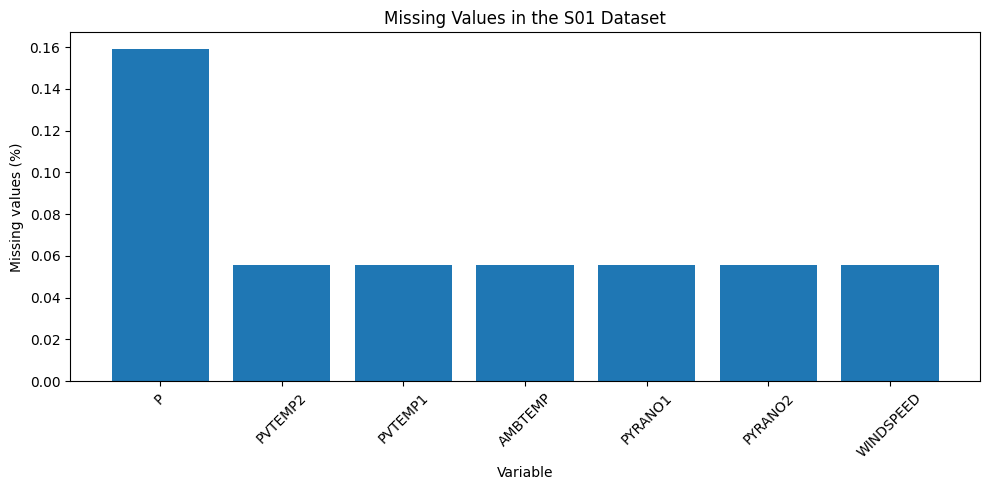

In [9]:
# Visualize missing values across all sensor variables
plt.figure(figsize=(10, 5))
plt.bar(missing_table.index, missing_table["missing_%"])
plt.ylabel("Missing values (%)")
plt.xlabel("Variable")
plt.title("Missing Values in the S01 Dataset")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "figure_01_missing_values.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 2.3 Descriptive Statistics


In [10]:
descriptive_stats = df_raw[sensor_cols].describe().T
descriptive_stats["missing"] = df_raw[sensor_cols].isna().sum()

display(descriptive_stats)

descriptive_stats.to_csv(
    OUTPUT_DIR / "table_03_descriptive_statistics.csv"
)

,count,mean,std,min,25%,50%,75%,max,missing
PVTEMP1,210411.0,33.536977,12.900306,0.00,24.464970,27.000000,42.623817,77.32,117
PVTEMP2,210411.0,33.663820,12.733954,0.00,24.696054,27.184992,42.651981,76.22,117
AMBTEMP,210411.0,28.369712,6.147621,0.00,25.010000,27.470000,31.920000,50.00,117
PYRANO1,210411.0,230.669022,324.479681,0.00,0.552991,4.570449,430.260000,1343.13,117
PYRANO2,210411.0,229.712003,323.382608,0.00,0.463939,3.870000,431.615000,1354.31,117
WINDSPEED,210411.0,7.567913,17.770772,0.00,0.773432,1.640000,2.673762,60.00,117
P,210193.0,1067.963720,1500.236386,-6.82,0.000000,0.000000,2114.770000,5552.26,335


## 2.4 Time-Series Visualization

A sample week of 5-minute power generation data is shown to illustrate the daily solar cycle present in the dataset.

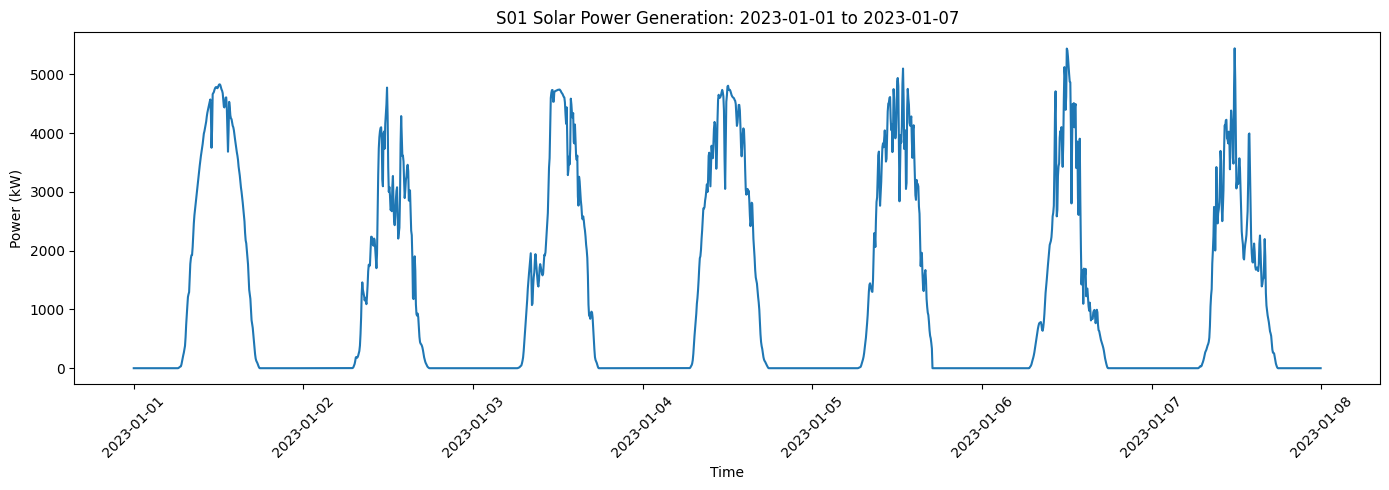

In [11]:
# Automatically select the first 7 complete calendar days available
plot_start = df_raw["timestamp"].min().normalize()
plot_end = plot_start + pd.Timedelta(days=7)

sample_week = df_raw[
    (df_raw["timestamp"] >= plot_start) &
    (df_raw["timestamp"] < plot_end)
]

plt.figure(figsize=(14, 5))
plt.plot(sample_week["timestamp"], sample_week["P"])
plt.xlabel("Time")
plt.ylabel("Power (kW)")
plt.title(f"S01 Solar Power Generation: {plot_start.date()} to {(plot_end - pd.Timedelta(days=1)).date()}")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "figure_02_power_timeseries_sample_week.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 2.5 Mean Daily Solar Power Profile

The mean power at each time of day is computed separately for 2023 and 2024 to observe the typical daily generation pattern and any year-to-year differences.

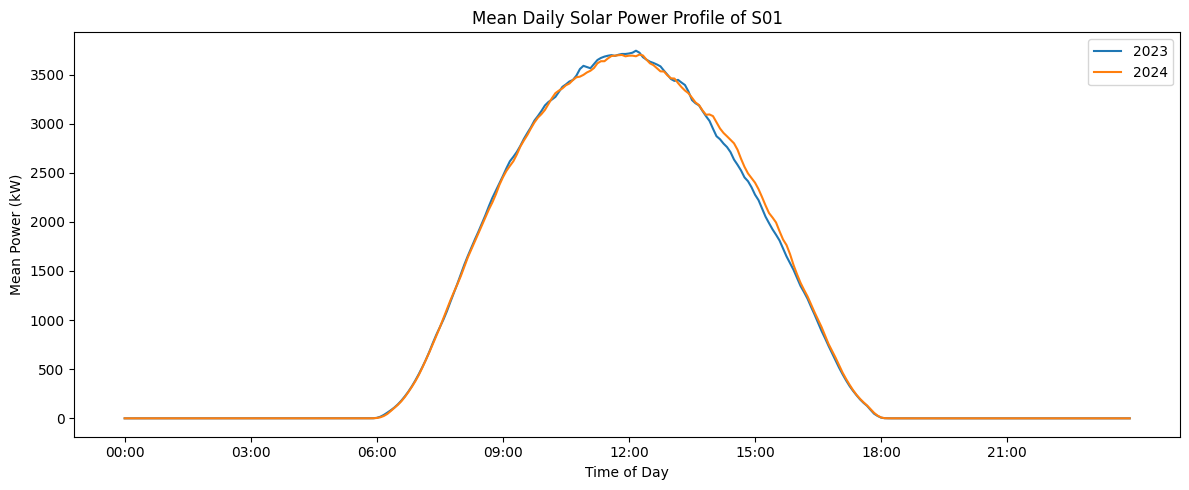

In [12]:
eda_profile = df_raw.copy()

eda_profile["year"] = eda_profile["timestamp"].dt.year
eda_profile["time_of_day"] = eda_profile["timestamp"].dt.strftime("%H:%M")

daily_profile = (
    eda_profile
    .groupby(["year", "time_of_day"], as_index=False)["P"]
    .mean()
)

plt.figure(figsize=(12, 5))

for year in sorted(daily_profile["year"].unique()):
    temp = daily_profile[daily_profile["year"] == year]
    plt.plot(
        np.arange(len(temp)),
        temp["P"],
        label=str(year)
    )

# Tick every 3 hours = 36 samples at 5-min resolution
tick_positions = np.arange(0, 288, 36)
tick_labels = [f"{h:02d}:00" for h in range(0, 24, 3)]

plt.xticks(tick_positions, tick_labels)
plt.xlabel("Time of Day")
plt.ylabel("Mean Power (kW)")
plt.title("Mean Daily Solar Power Profile of S01")
plt.legend()
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "figure_03_mean_daily_power_profile.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 2.6 Monthly Energy Pattern

Since power (P) is recorded in kW at 5-minute intervals, the approximate energy for each record is P × (5/60) kWh. Monthly totals show the seasonal variation across the two study years.

,month,energy_MWh
0,2023-01,841.240683
1,2023-02,811.477403
2,2023-03,891.831515
3,2023-04,762.335183
4,2023-05,780.531861
5,2023-06,699.891669
6,2023-07,719.104003
7,2023-08,753.957314
8,2023-09,619.757566
9,2023-10,753.160565


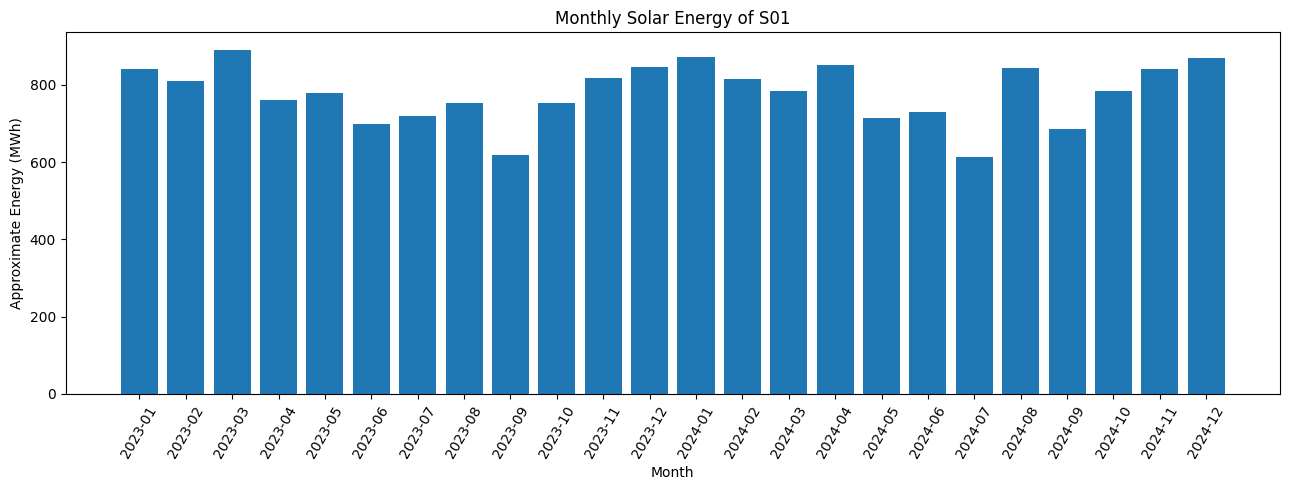

In [13]:
energy_df = df_raw[["timestamp", "P"]].copy()

# Do not fill missing target values; only valid measurements contribute
energy_df["energy_kWh"] = energy_df["P"] * (5 / 60)
energy_df["month"] = energy_df["timestamp"].dt.to_period("M").astype(str)

monthly_energy = (
    energy_df
    .groupby("month", as_index=False)["energy_kWh"]
    .sum()
)

monthly_energy["energy_MWh"] = monthly_energy["energy_kWh"] / 1000

display(monthly_energy[["month", "energy_MWh"]])

monthly_energy.to_csv(
    OUTPUT_DIR / "table_04_monthly_energy.csv",
    index=False
)

plt.figure(figsize=(13, 5))
plt.bar(monthly_energy["month"], monthly_energy["energy_MWh"])
plt.xlabel("Month")
plt.ylabel("Approximate Energy (MWh)")
plt.title("Monthly Solar Energy of S01")
plt.xticks(rotation=60)
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "figure_04_monthly_energy.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 2.7 Distribution of Power Generation

Solar power data contain many zero values at night. We show two distributions: one for all 24-hour observations and one limited to daytime hours (06:00–18:00). This also illustrates why percentage-based metrics such as MAPE become unstable near zero generation.

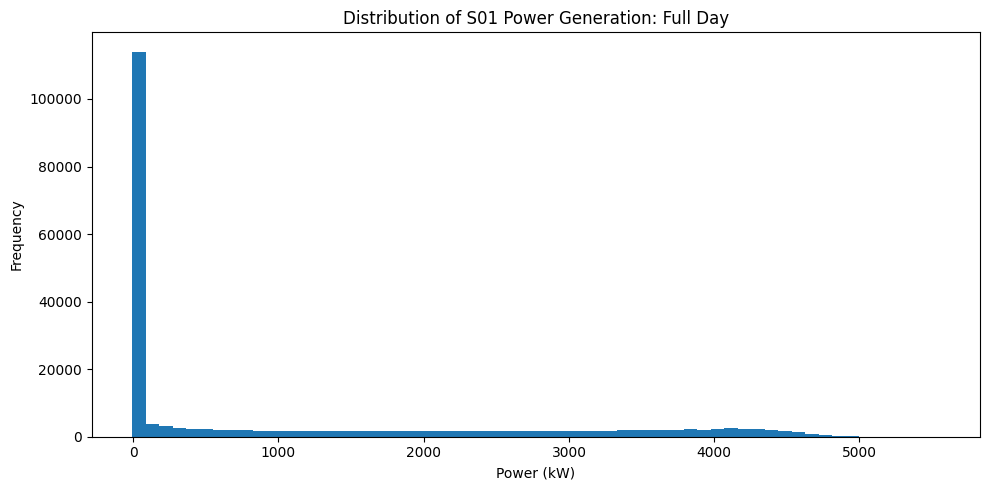

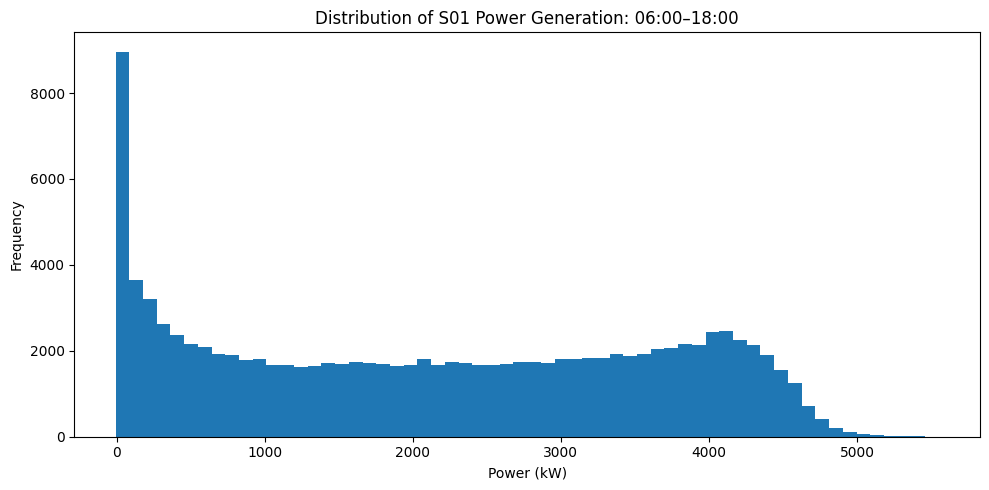

Full-day skewness: 1.0865
Daylight skewness: 0.0675


In [14]:
hour_decimal = (
    df_raw["timestamp"].dt.hour +
    df_raw["timestamp"].dt.minute / 60
)

daylight_mask = (hour_decimal >= 6) & (hour_decimal < 18)

plt.figure(figsize=(10, 5))
plt.hist(df_raw["P"].dropna(), bins=60)
plt.xlabel("Power (kW)")
plt.ylabel("Frequency")
plt.title("Distribution of S01 Power Generation: Full Day")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "figure_05_power_distribution_full_day.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

plt.figure(figsize=(10, 5))
plt.hist(df_raw.loc[daylight_mask, "P"].dropna(), bins=60)
plt.xlabel("Power (kW)")
plt.ylabel("Frequency")
plt.title("Distribution of S01 Power Generation: 06:00–18:00")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "figure_06_power_distribution_daylight.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Full-day skewness:", round(df_raw["P"].skew(), 4))
print(
    "Daylight skewness:",
    round(df_raw.loc[daylight_mask, "P"].skew(), 4)
)

## 2.8 Outlier Examination

Boxplots are used to visually inspect each key variable for unusual observations. Points beyond the whiskers indicate values that fall outside the typical interquartile range.

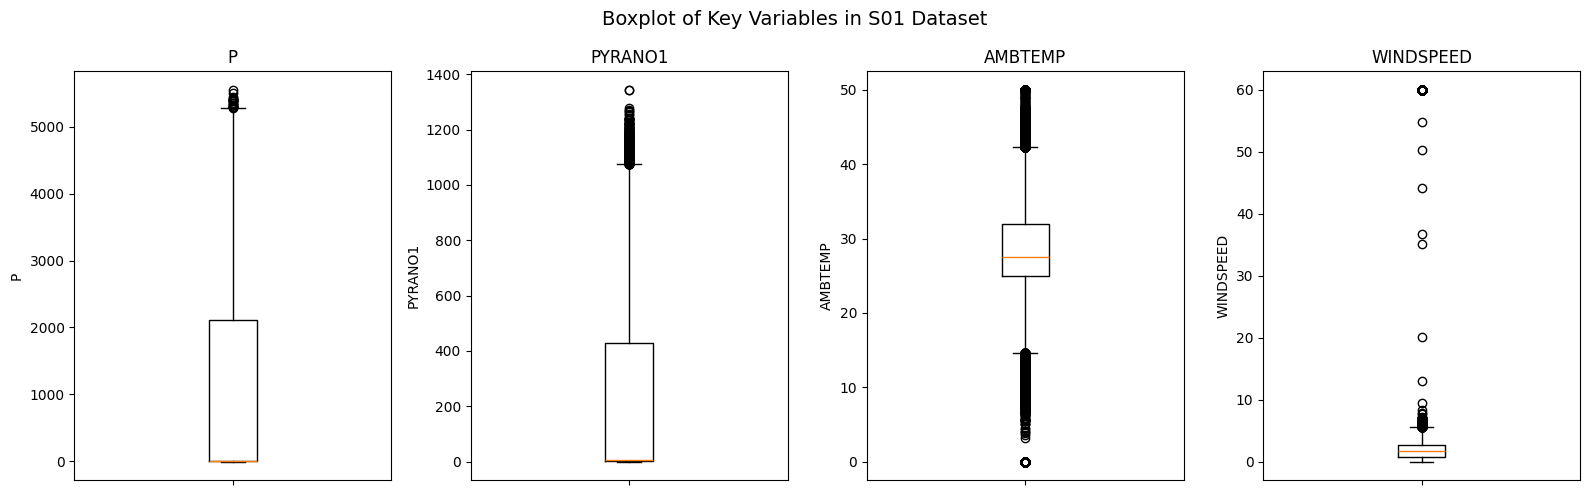

Observations beyond IQR fences (potential outliers):
--------------------------------------------------
  P           : 22 observations (0.01%)
  PYRANO1     : 636 observations (0.30%)
  AMBTEMP     : 7,190 observations (3.42%)
  WINDSPEED   : 21,839 observations (10.38%)


In [15]:
key_vars = ["P", "PYRANO1", "AMBTEMP", "WINDSPEED"]

fig, axes = plt.subplots(1, len(key_vars), figsize=(16, 5))

for ax, col in zip(axes, key_vars):
    ax.boxplot(df_raw[col].dropna(), vert=True)
    ax.set_title(col)
    ax.set_ylabel(col)
    ax.set_xticklabels([""])

plt.suptitle("Boxplot of Key Variables in S01 Dataset", fontsize=14)
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "figure_06_boxplots.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Count observations beyond the IQR fences for each variable
print("Observations beyond IQR fences (potential outliers):")
print("-" * 50)
for col in key_vars:
    vals = df_raw[col].dropna()
    q1 = vals.quantile(0.25)
    q3 = vals.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_outliers = ((vals < lower) | (vals > upper)).sum()
    print(f"  {col:12s}: {n_outliers:,} observations ({n_outliers / len(vals) * 100:.2f}%)")

## 2.9 Data Distribution and Skewness

We compute the skewness of each variable to understand the shape of its distribution. Positive skewness indicates a right-tailed distribution, while values near zero suggest approximate symmetry.

In [16]:
skewness = df_raw[sensor_cols].skew().round(3)
kurtosis = df_raw[sensor_cols].kurtosis().round(3)

dist_summary = pd.DataFrame({
    "skewness": skewness,
    "kurtosis": kurtosis
})

display(dist_summary)

dist_summary.to_csv(
    OUTPUT_DIR / "table_04_skewness_kurtosis.csv"
)

print("\nInterpretation:")
for col in sensor_cols:
    sk = skewness[col]
    if abs(sk) < 0.5:
        shape = "approximately symmetric"
    elif sk > 0:
        shape = "right-skewed (positively skewed)"
    else:
        shape = "left-skewed (negatively skewed)"
    print(f"  {col:12s}: {sk:+.3f} — {shape}")

,skewness,kurtosis
PVTEMP1,0.923,-0.206
PVTEMP2,0.920,-0.206
AMBTEMP,0.268,2.466
PYRANO1,1.159,-0.106
PYRANO2,1.155,-0.120
WINDSPEED,2.600,4.797
P,1.086,-0.345



Interpretation:
  PVTEMP1     : +0.923 — right-skewed (positively skewed)
  PVTEMP2     : +0.920 — right-skewed (positively skewed)
  AMBTEMP     : +0.268 — approximately symmetric
  PYRANO1     : +1.159 — right-skewed (positively skewed)
  PYRANO2     : +1.155 — right-skewed (positively skewed)
  WINDSPEED   : +2.600 — right-skewed (positively skewed)
  P           : +1.086 — right-skewed (positively skewed)


## 2.10 Solar Irradiance vs. Power Generation

We investigate the relationship between measured solar irradiance (PYRANO1) and PV power output. A reproducible sample is used for plotting when the dataset is large.

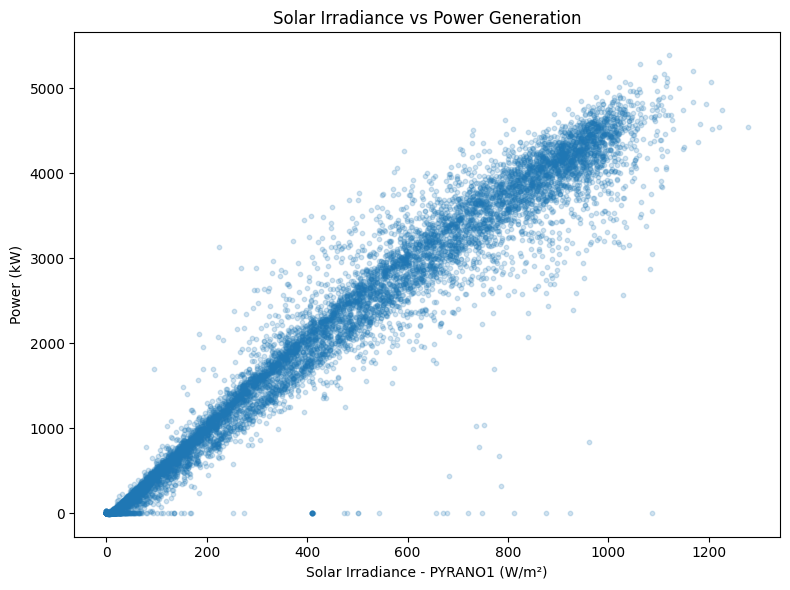

Pearson correlation between PYRANO1 and P: 0.9871


In [17]:
scatter_df = df_raw[["PYRANO1", "P"]].dropna()

if len(scatter_df) > 20000:
    scatter_df = scatter_df.sample(
        20000,
        random_state=RANDOM_STATE
    )

plt.figure(figsize=(8, 6))
plt.scatter(
    scatter_df["PYRANO1"],
    scatter_df["P"],
    alpha=0.2,
    s=10
)
plt.xlabel("Solar Irradiance - PYRANO1 (W/m²)")
plt.ylabel("Power (kW)")
plt.title("Solar Irradiance vs Power Generation")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "figure_07_irradiance_vs_power.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

irradiance_corr = df_raw[["PYRANO1", "P"]].corr().iloc[0, 1]
print("Pearson correlation between PYRANO1 and P:", round(irradiance_corr, 4))

## 2.11 Correlation Matrix


,PVTEMP1,PVTEMP2,AMBTEMP,PYRANO1,PYRANO2,WINDSPEED,P
PVTEMP1,1.000,1.000,0.626,0.935,0.932,0.015,0.917
PVTEMP2,1.000,1.000,0.627,0.935,0.932,0.017,0.918
AMBTEMP,0.626,0.627,1.000,0.472,0.466,0.070,0.452
PYRANO1,0.935,0.935,0.472,1.000,0.999,-0.005,0.987
PYRANO2,0.932,0.932,0.466,0.999,1.000,0.001,0.988
WINDSPEED,0.015,0.017,0.070,-0.005,0.001,1.000,-0.002
P,0.917,0.918,0.452,0.987,0.988,-0.002,1.000


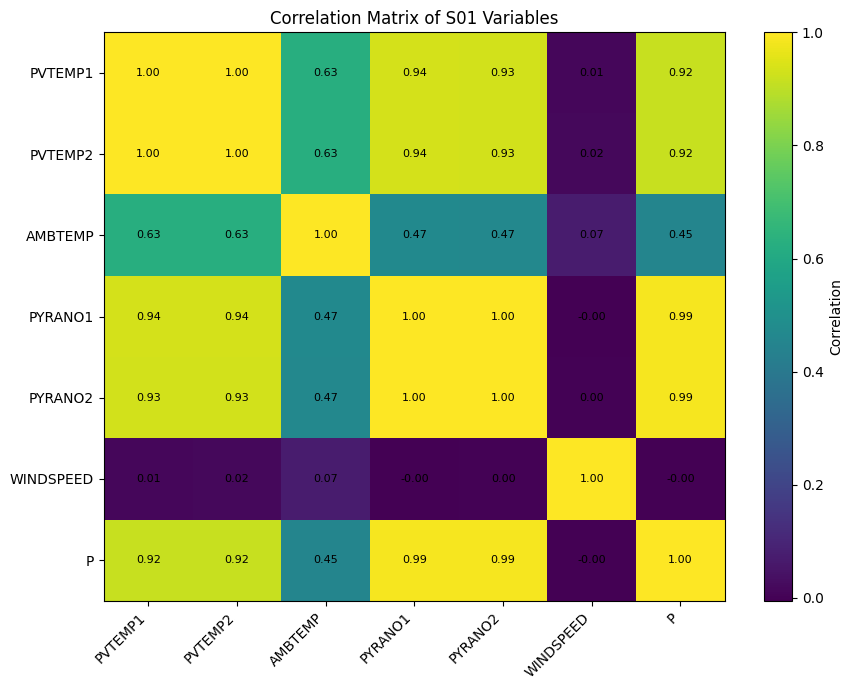

In [18]:
corr_matrix = df_raw[sensor_cols].corr()

display(corr_matrix.round(3))

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr_matrix.values, aspect="auto")

ax.set_xticks(np.arange(len(corr_matrix.columns)))
ax.set_yticks(np.arange(len(corr_matrix.index)))
ax.set_xticklabels(corr_matrix.columns, rotation=45, ha="right")
ax.set_yticklabels(corr_matrix.index)

for i in range(len(corr_matrix.index)):
    for j in range(len(corr_matrix.columns)):
        ax.text(
            j, i,
            f"{corr_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

fig.colorbar(im, ax=ax, label="Correlation")
ax.set_title("Correlation Matrix of S01 Variables")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "figure_08_correlation_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 2.12 Preliminary Findings Summary

A concise numerical summary of the key findings from the EDA, used as reference when writing the Preliminary Results section of the proposal.

In [19]:
valid_p = df_raw["P"].dropna()

summary = {
    "Study period": (
        f"{df_raw['timestamp'].min().date()} to "
        f"{df_raw['timestamp'].max().date()}"
    ),
    "5-min records": len(df_raw),
    "Unique calendar days": df_raw["timestamp"].dt.date.nunique(),
    "Duplicate timestamps": int(df_raw["timestamp"].duplicated().sum()),
    "Missing P values": int(df_raw["P"].isna().sum()),
    "Mean power (kW)": valid_p.mean(),
    "Maximum observed power (kW)": valid_p.max(),
    "Power skewness": valid_p.skew(),
    "PYRANO1-P correlation": irradiance_corr
}

summary_df = pd.DataFrame(
    summary.items(),
    columns=["Item", "Value"]
)

display(summary_df)

summary_df.to_csv(
    OUTPUT_DIR / "table_05_preliminary_summary.csv",
    index=False
)

print("\n--- Proposal writing helper ---")
print(
    f"The dataset covers {summary['Study period']} and contains "
    f"{summary['5-min records']:,} five-minute records."
)
print(
    f"The observed correlation between PYRANO1 and power generation is "
    f"{summary['PYRANO1-P correlation']:.4f}."
)
print(
    f"The maximum observed power is "
    f"{summary['Maximum observed power (kW)']:.2f} kW."
)
print("\nUse these statements only after checking the EDA figures above.")

,Item,Value
0,Study period,2023-01-01 to 2024-12-31
1,5-min records,210528
2,Unique calendar days,731
3,Duplicate timestamps,0
4,Missing P values,335
5,Mean power (kW),1067.96372
6,Maximum observed power (kW),5552.26
7,Power skewness,1.08646
8,PYRANO1-P correlation,0.987053



--- Proposal writing helper ---
The dataset covers 2023-01-01 to 2024-12-31 and contains 210,528 five-minute records.
The observed correlation between PYRANO1 and power generation is 0.9871.
The maximum observed power is 5552.26 kW.

Use these statements only after checking the EDA figures above.


# 3. Data Preprocessing

The original 5-minute measurements are aggregated into 15-minute intervals to align with PEA's standard metering resolution. For each 15-minute window, the mean of the available 5-minute readings is computed.

For the target variable (power generation), an interval is set to missing if fewer than three valid 5-minute measurements are present, since a reliable actual value is required for model evaluation.

In [20]:
df = df_raw.copy()
df = df.drop_duplicates(subset="timestamp", keep="first")
df = df.sort_values("timestamp")
df = df.set_index("timestamp")

numeric_cols = [
    "PVTEMP1",
    "PVTEMP2",
    "AMBTEMP",
    "PYRANO1",
    "PYRANO2",
    "WINDSPEED",
    "P"
]

# Note: raw P is kept as is (small negative values near sunrise/sunset are preserved).
# Clipping to the 0-6,000 kW operating range is decided at the modelling stage.

# Mean values in each 15-min window
target_index = pd.date_range(STUDY_START, pd.Timestamp(STUDY_END)+pd.Timedelta(days=1), freq="15min", inclusive="left")
df_15 = df[numeric_cols].resample("15min").mean().reindex(target_index)

# Count how many valid 5-min observations contributed to each 15-min P value
p_count = df["P"].resample("15min").count().reindex(target_index, fill_value=0)
df_15["P_count_5min"] = p_count

# Strict target: need all 3 expected measurements
df_15.loc[df_15["P_count_5min"] < 3, "P"] = np.nan

print("15-min rows:", f"{len(df_15):,}")
print("Incomplete target intervals:", int((df_15["P_count_5min"] < 3).sum()))
print("Missing 15-min target P:", int(df_15["P"].isna().sum()))

display(df_15.head())

# Round to avoid floating-point artifacts such as 15.316666666666668
# (Excel can flag these long values as text)
df_15 = df_15.round(4)

df_15.to_csv(
    OUTPUT_DIR / "S01_2023_2024_15min_processed.csv"
)


15-min rows: 70,176
Incomplete target intervals: 120
Missing 15-min target P: 120


,PVTEMP1,PVTEMP2,AMBTEMP,PYRANO1,PYRANO2,WINDSPEED,P,P_count_5min
2023-01-01 00:00:00,20.303333,20.633333,21.040000,0.606667,0.416667,3.683333,0.0,3
2023-01-01 00:15:00,19.956667,20.286667,20.783333,0.613333,0.420000,3.240000,0.0,3
2023-01-01 00:30:00,19.783333,20.110000,20.530000,0.620000,0.420000,2.900000,0.0,3
2023-01-01 00:45:00,19.600000,19.933333,20.266667,0.630000,0.416667,3.236667,0.0,3
2023-01-01 01:00:00,19.480000,19.780000,19.983333,0.633333,0.406667,3.286667,0.0,3


### 15-Minute Completeness by Day

A complete day should contain 96 valid 15-minute target intervals. We check how many days meet this criterion.

In [21]:
daily_completeness = (
    df_15["P"]
    .notna()
    .groupby(df_15.index.date)
    .sum()
    .rename("valid_intervals")
    .to_frame()
)

daily_completeness["complete_96"] = (
    daily_completeness["valid_intervals"] == 96
)

print(
    "Complete days:",
    int(daily_completeness["complete_96"].sum()),
    "/",
    len(daily_completeness)
)

display(daily_completeness["valid_intervals"].value_counts().sort_index().tail(15))

Complete days: 722 / 731


valid_intervals
53      1
71      2
85      1
92      2
93      2
94      1
96    722
Name: count, dtype: int64

Day-level completeness summary
  Complete (96/96):     722
  Partial (80–95):      6
  Low (<80 intervals):  3
  Total days:           731

9 days with fewer than 96 valid intervals:


,valid_intervals,complete_96,low_completeness
2023-11-26,53,False,True
2023-04-24,71,False,True
2023-11-27,71,False,True
2023-03-20,85,False,False
2023-06-09,92,False,False
2023-05-29,92,False,False
2023-05-01,93,False,False
2023-03-21,93,False,False
2023-09-06,94,False,False


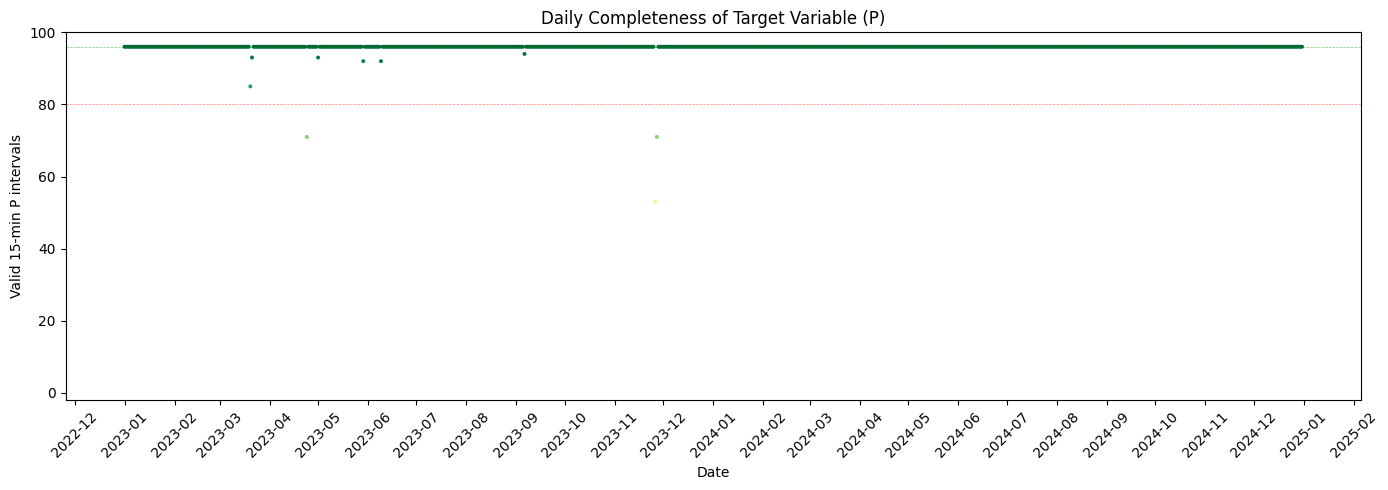

In [22]:
#  Day completeness with flags
daily_completeness["low_completeness"] = daily_completeness["valid_intervals"] < 80

complete_days = int(daily_completeness["complete_96"].sum())
low_days = int(daily_completeness["low_completeness"].sum())
partial_days = int(
    (~daily_completeness["complete_96"] & ~daily_completeness["low_completeness"]).sum()
)
total_days = len(daily_completeness)

print("Day-level completeness summary")
print("=" * 50)
print(f"  Complete (96/96):     {complete_days}")
print(f"  Partial (80–95):      {partial_days}")
print(f"  Low (<80 intervals):  {low_days}")
print(f"  Total days:           {total_days}")

# Show all non-complete days
incomplete = daily_completeness[~daily_completeness["complete_96"]].copy()
incomplete.index = pd.to_datetime(incomplete.index)
print(f"\n{len(incomplete)} days with fewer than 96 valid intervals:")
display(incomplete.sort_values("valid_intervals"))

# ── Calendar heatmap: valid P intervals per day ──
import matplotlib.dates as mdates

heatmap_df = daily_completeness.copy()
heatmap_df.index = pd.to_datetime(heatmap_df.index)

fig, ax = plt.subplots(figsize=(14, 5))
ax.scatter(
    heatmap_df.index,
    heatmap_df["valid_intervals"],
    c=heatmap_df["valid_intervals"],
    cmap="RdYlGn",
    vmin=0, vmax=96,
    s=8,
    edgecolors="none"
)
ax.axhline(96, color="green", linewidth=0.5, linestyle="--", alpha=0.5)
ax.axhline(80, color="red", linewidth=0.5, linestyle="--", alpha=0.5)
ax.set_xlabel("Date")
ax.set_ylabel("Valid 15-min P intervals")
ax.set_title("Daily Completeness of Target Variable (P)")
ax.set_ylim(-2, 100)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "figure_09_daily_completeness.png", dpi=150)
plt.show()

## 3 Sensor quality rules

Weather flags use the existing study heuristics. Frozen-sensor detection uses
trailing run length and masks only the 12th consecutive reading onward, without
changing earlier observations. P is not imputed or masked by weather rules.
Threshold definitions and affected-row counts are exported for review.


In [23]:
from src.data_quality import clean_sensor_observations
df = df_raw.drop_duplicates("timestamp").sort_values("timestamp").set_index("timestamp")
df, summary_df = clean_sensor_observations(df, output_dir=OUTPUT_DIR)
display(summary_df)


,Rule,Rows affected,Handling
0,Negative P,864,Flag only; P retained
1,WINDSPEED equals 60,21609,Wind set to missing
2,Other wind above 20 m/s,6,Wind set to missing
3,All weather sensors equal zero,659,Weather set to missing
4,AMBTEMP equals 50 C,2484,Temperature set to missing
5,Frozen temperature run from reading 12 onward,460,Weather set to missing causally


### Aggregate cleaned observations

Require three valid 5-minute P readings for each 15-minute target. Reindex to the fixed study calendar.


In [24]:
#  Resample to 15-minute intervals (on masked data)
numeric_cols = ["PVTEMP1", "PVTEMP2", "AMBTEMP", "PYRANO1", "PYRANO2", "WINDSPEED", "P"]

target_index = pd.date_range(STUDY_START, pd.Timestamp(STUDY_END)+pd.Timedelta(days=1), freq="15min", inclusive="left")
df_15 = df[numeric_cols].resample("15min").mean().reindex(target_index)

# Count how many valid 5-min P observations contributed to each 15-min interval
p_count = df["P"].resample("15min").count().reindex(target_index, fill_value=0)
df_15["P_count_5min"] = p_count

# Strict target: need all 3 expected measurements
df_15.loc[df_15["P_count_5min"] < 3, "P"] = np.nan

# Carry flag columns forward 
flag_cols = [c for c in df.columns if c.startswith("flag_")]
for fc in flag_cols:
    df_15[fc] = df[fc].resample("15min").max()

print("15-min rows:", f"{len(df_15):,}")
print("Missing 15-min target P:", int(df_15["P"].isna().sum()))
print(f"Flag columns carried: {flag_cols}")

df_15 = df_15.round(4)
df_15.to_csv(OUTPUT_DIR / "S01_2023_2024_15min_processed.csv")

display(df_15.head())


15-min rows: 70,176
Missing 15-min target P: 120
Flag columns carried: ['flag_negative_P', 'flag_wind_stuck_60', 'flag_wind_spike', 'flag_logger_dropout', 'flag_ambtemp_stuck', 'flag_stale_data', 'flag_review_date']


,PVTEMP1,PVTEMP2,AMBTEMP,PYRANO1,PYRANO2,WINDSPEED,P,P_count_5min,flag_negative_P,flag_wind_stuck_60,flag_wind_spike,flag_logger_dropout,flag_ambtemp_stuck,flag_stale_data,flag_review_date
2023-01-01 00:00:00,20.3033,20.6333,21.0400,0.6067,0.4167,3.6833,0.0,3,False,False,False,False,False,False,False
2023-01-01 00:15:00,19.9567,20.2867,20.7833,0.6133,0.4200,3.2400,0.0,3,False,False,False,False,False,False,False
2023-01-01 00:30:00,19.7833,20.1100,20.5300,0.6200,0.4200,2.9000,0.0,3,False,False,False,False,False,False,False
2023-01-01 00:45:00,19.6000,19.9333,20.2667,0.6300,0.4167,3.2367,0.0,3,False,False,False,False,False,False,False
2023-01-01 01:00:00,19.4800,19.7800,19.9833,0.6333,0.4067,3.2867,0.0,3,False,False,False,False,False,False,False


### 15-Minute Completeness by Day

A complete day should contain 96 valid 15-minute target intervals. We will check how many days meet this after sensor masking processes.

Day-level completeness summary (after sensor masking)
  Complete (96/96):     722
  Partial (80–95):      6
  Low (<80 intervals):  3
  Total days:           731

9 days with fewer than 96 valid intervals:


,valid_intervals,complete_96,low_completeness
2023-11-26,53,False,True
2023-04-24,71,False,True
2023-11-27,71,False,True
2023-03-20,85,False,False
2023-06-09,92,False,False
2023-05-29,92,False,False
2023-05-01,93,False,False
2023-03-21,93,False,False
2023-09-06,94,False,False


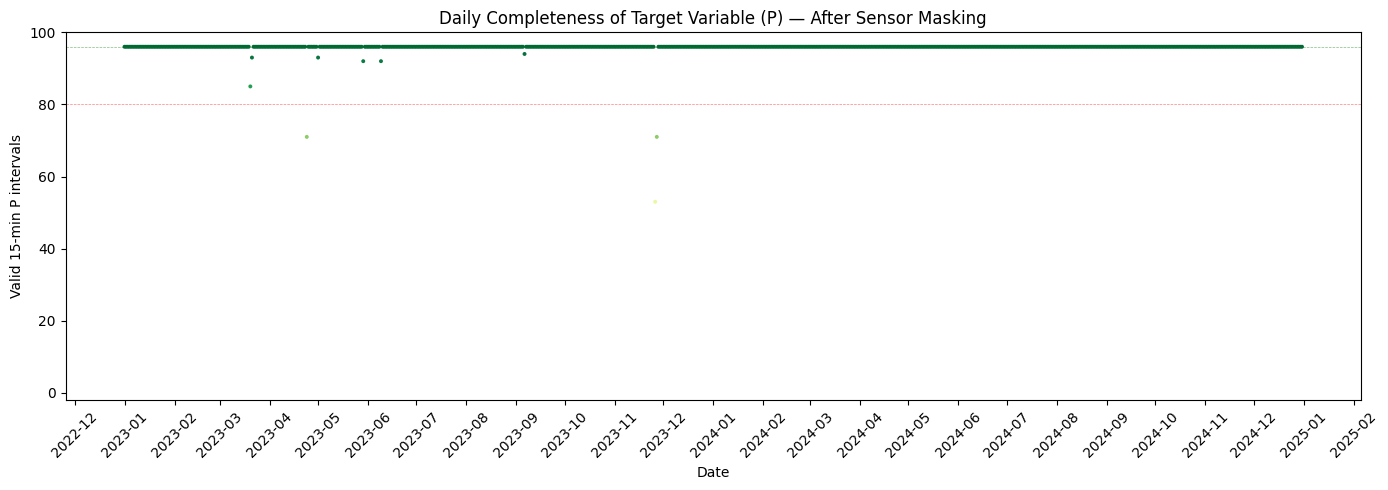

In [25]:
# Day completeness (re-run on cleaned data)
daily_completeness = (
    df_15["P"]
    .notna()
    .groupby(df_15.index.date)
    .sum()
    .rename("valid_intervals")
    .to_frame()
)

daily_completeness["complete_96"] = daily_completeness["valid_intervals"] == 96
daily_completeness["low_completeness"] = daily_completeness["valid_intervals"] < 80

complete_days = int(daily_completeness["complete_96"].sum())
low_days = int(daily_completeness["low_completeness"].sum())
partial_days = int(
    (~daily_completeness["complete_96"] & ~daily_completeness["low_completeness"]).sum()
)
total_days = len(daily_completeness)

print("Day-level completeness summary (after sensor masking)")
print("=" * 50)
print(f"  Complete (96/96):     {complete_days}")
print(f"  Partial (80–95):      {partial_days}")
print(f"  Low (<80 intervals):  {low_days}")
print(f"  Total days:           {total_days}")


incomplete = daily_completeness[~daily_completeness["complete_96"]].copy()
incomplete.index = pd.to_datetime(incomplete.index)
print(f"\n{len(incomplete)} days with fewer than 96 valid intervals:")
display(incomplete.sort_values("valid_intervals"))

# ── Calendar heatmap ──
import matplotlib.dates as mdates

heatmap_df = daily_completeness.copy()
heatmap_df.index = pd.to_datetime(heatmap_df.index)

fig, ax = plt.subplots(figsize=(14, 5))
ax.scatter(
    heatmap_df.index,
    heatmap_df["valid_intervals"],
    c=heatmap_df["valid_intervals"],
    cmap="RdYlGn",
    vmin=0, vmax=96,
    s=8,
    edgecolors="none"
)
ax.axhline(96, color="green", linewidth=0.5, linestyle="--", alpha=0.5)
ax.axhline(80, color="red", linewidth=0.5, linestyle="--", alpha=0.5)
ax.set_xlabel("Date")
ax.set_ylabel("Valid 15-min P intervals")
ax.set_title("Daily Completeness of Target Variable (P) — After Sensor Masking")
ax.set_ylim(-2, 100)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "figure_09_daily_completeness.png", dpi=150)
plt.show()

In [26]:
from src.data_quality import run_completeness_audit
completeness_audit, monthly_target, coverage_report = run_completeness_audit(
    df_raw,daily_completeness,coverage,excel_files,OUTPUT_DIR,
    study_start=STUDY_START,study_end=STUDY_END,
)
display(completeness_audit.loc[~completeness_audit.complete_96])


Corrected target completeness by month


,year,month,calendar_days,source_sheet_days,raw_loaded_days,complete_target_days,incomplete_target_days,valid_target_intervals,expected_target_intervals,target_day_coverage_%,target_interval_coverage_%
0,2023,1,31,31,31,31,0,2976,2976,100.00,100.00
1,2023,2,28,28,28,28,0,2688,2688,100.00,100.00
2,2023,3,31,31,31,29,2,2962,2976,93.55,99.53
3,2023,4,30,30,30,29,1,2855,2880,96.67,99.13
4,2023,5,31,31,31,29,2,2969,2976,93.55,99.76
5,2023,6,30,30,30,29,1,2876,2880,96.67,99.86
6,2023,7,31,31,31,31,0,2976,2976,100.00,100.00
7,2023,8,31,31,31,31,0,2976,2976,100.00,100.00
8,2023,9,30,30,30,29,1,2878,2880,96.67,99.93
9,2023,10,31,31,31,31,0,2976,2976,100.00,100.00


Source/loader status counts


,days
source_loader_status,
loaded as expected,722
source P values missing,9


Missing target dates saved to table_01_missing_target_dates.csv


,source_sheet_present,source_5min_rows,source_p_missing_5min,loaded_5min_rows,loaded_unique_timestamps,raw_p_missing_5min,valid_intervals,complete_96,low_completeness,source_loader_status,raw_row_coverage_%,timestamp_row_difference,P_missing_difference,target_interval_coverage_%,target_status
date,,,,,,,,,,,,,,,
2023-03-20,True,288,29,288,288,29,85,False,False,source P values missing,100.0,0,0,88.54,incomplete P; intervals are excluded from loss
2023-03-21,True,288,7,288,288,7,93,False,False,source P values missing,100.0,0,0,96.88,incomplete P; intervals are excluded from loss
2023-04-24,True,288,73,288,288,73,71,False,True,source P values missing,100.0,0,0,73.96,incomplete P; intervals are excluded from loss
2023-05-01,True,288,6,288,288,6,93,False,False,source P values missing,100.0,0,0,96.88,incomplete P; intervals are excluded from loss
2023-05-29,True,288,8,288,288,8,92,False,False,source P values missing,100.0,0,0,95.83,incomplete P; intervals are excluded from loss
2023-06-09,True,288,9,288,288,9,92,False,False,source P values missing,100.0,0,0,95.83,incomplete P; intervals are excluded from loss
2023-09-06,True,288,4,288,288,4,94,False,False,source P values missing,100.0,0,0,97.92,incomplete P; intervals are excluded from loss
2023-11-26,True,288,125,288,288,125,53,False,True,source P values missing,100.0,0,0,55.21,incomplete P; intervals are excluded from loss
2023-11-27,True,288,74,288,288,74,71,False,True,source P values missing,100.0,0,0,73.96,incomplete P; intervals are excluded from loss


### Day eligibility and paired sensors

Days with fewer than 80/96 valid P targets are excluded under the study policy.
For retained partial days, only valid targets are fitted/scored. Dates previously
listed as possible outages are retained for review unless they fail this rule or
have a documented manual exclusion. Weather flags alone do not prove an outage.
The exported daily log records observed counts, flags, eligibility, and reasons.


In [27]:
from src.data_quality import apply_day_quality_policy
df_15["irradiance"] = df_15[["PYRANO1","PYRANO2"]].mean(axis=1)
df_15["pv_temp"] = df_15[["PVTEMP1","PVTEMP2"]].mean(axis=1)
df_15 = df_15.drop(columns=["PYRANO1","PYRANO2","PVTEMP1","PVTEMP2"])
df_15, day_quality_log = apply_day_quality_policy(
    df_15, output_dir=OUTPUT_DIR, min_valid_targets=80,
    manual_exclusions=MANUAL_EXCLUSIONS,
)
EXCLUDE_DATES = day_quality_log.index[day_quality_log.excluded]
feature_cols = ["AMBTEMP","WINDSPEED","irradiance","pv_temp"]
print("Excluded days:", len(EXCLUDE_DATES))
print("Retained dates:", int((~day_quality_log.excluded).sum()))
display(day_quality_log.loc[day_quality_log.excluded | day_quality_log.legacy_review_date])


Excluded days: 3
Retained dates: 728


,valid_target_intervals,complete_96,legacy_review_date,manual_reason,excluded,reason,flag_negative_P_intervals,flag_wind_stuck_60_intervals,flag_wind_spike_intervals,flag_logger_dropout_intervals,flag_ambtemp_stuck_intervals,flag_stale_data_intervals,flag_review_date_intervals
date,,,,,,,,,,,,,
2023-04-24,71,False,True,,True,Fewer than 80/96 valid P targets (71/96),1,0,0,0,0,0,96
2023-04-25,96,True,True,,False,Retained for review; no confirmed manual exclu...,0,0,0,96,0,0,96
2023-07-30,96,True,True,,False,Retained for review; no confirmed manual exclu...,2,96,0,0,0,0,96
2023-11-26,53,False,True,,True,Fewer than 80/96 valid P targets (53/96),0,0,0,0,0,37,96
2023-11-27,71,False,True,,True,Fewer than 80/96 valid P targets (71/96),0,0,0,0,0,0,96
2024-03-26,96,True,True,,False,Retained for review; no confirmed manual exclu...,1,0,0,0,0,0,96
2024-04-26,96,True,True,,False,Retained for review; no confirmed manual exclu...,0,0,0,0,0,38,96


## 3.5 Load day-ahead forecast weather

Open-Meteo ERA5 reanalysis data at 15-minute resolution provides
weather conditions for the target day. These represent information a
real operator would have access to via a weather API before issuing
the day-ahead forecast. Run `python -m src.fetch_weather` first.


In [28]:
from src.data_quality import load_forecast_weather

if FORECAST_WEATHER_PATH.exists():
    forecast_weather = load_forecast_weather(FORECAST_WEATHER_PATH)
    print(f"Date range: {forecast_weather.index.min()} to {forecast_weather.index.max()}")
    print(f"Columns: {forecast_weather.columns.tolist()}")
    # Correlation check: Open-Meteo GHI vs on-site pyranometer
    if "fcst_ghi" in forecast_weather.columns:
        merged = df_15[["irradiance", "P"]].join(
            forecast_weather["fcst_ghi"], how="inner"
        ).dropna()
        print(f"\nOpen-Meteo GHI vs on-site irradiance r={merged['irradiance'].corr(merged['fcst_ghi']):.3f}")
        print(f"Open-Meteo GHI vs power output       r={merged['P'].corr(merged['fcst_ghi']):.3f}")
else:
    forecast_weather = None
    print("No forecast weather file found; using original 17 features only.")
    print("To add forecast features, run: python -m src.fetch_weather")

Forecast weather loaded: 70176 rows, columns=['fcst_ghi', 'fcst_direct_rad', 'fcst_diffuse_rad', 'fcst_dni', 'fcst_sunshine_sec', 'fcst_temp', 'fcst_dewpoint', 'fcst_apparent_temp', 'fcst_humidity', 'fcst_vpd', 'fcst_pressure', 'fcst_precip', 'fcst_cloud', 'fcst_cloud_low', 'fcst_cloud_mid', 'fcst_cloud_high', 'fcst_wind', 'fcst_windgusts', 'nasa_ghi', 'nasa_clearsky_ghi', 'nasa_clearness_index', 'nasa_temp', 'nasa_humidity', 'nasa_wind', 'clearsky_ghi', 'clear_sky_index']
Date range: 2023-01-01 00:00:00 to 2024-12-31 23:45:00
Columns: ['fcst_ghi', 'fcst_direct_rad', 'fcst_diffuse_rad', 'fcst_dni', 'fcst_sunshine_sec', 'fcst_temp', 'fcst_dewpoint', 'fcst_apparent_temp', 'fcst_humidity', 'fcst_vpd', 'fcst_pressure', 'fcst_precip', 'fcst_cloud', 'fcst_cloud_low', 'fcst_cloud_mid', 'fcst_cloud_high', 'fcst_wind', 'fcst_windgusts', 'nasa_ghi', 'nasa_clearsky_ghi', 'nasa_clearness_index', 'nasa_temp', 'nasa_humidity', 'nasa_wind', 'clearsky_ghi', 'clear_sky_index']

Open-Meteo GHI vs on-sit

## 4 Chronological train and test split

The hold-out contains the last 20% of dates retained under the documented quality policy. Date ranges are recalculated on each run; old results must not be reused.


In [29]:
# Chronological train/test split on non-excluded days

# Keep raw clean data separate so walk-forward can re-impute per fold
df_clean_raw = df_15[~df_15["excluded"]].copy()
df_clean = df_clean_raw.copy()

all_dates = pd.Series(df_clean.index.normalize().unique()).sort_values().reset_index(drop=True)
n_days = len(all_dates)

split_idx = int(n_days * 0.8)
train_end_date = all_dates.iloc[split_idx - 1]

test_start_date = all_dates.iloc[split_idx]

df_train_raw = df_clean_raw[df_clean_raw.index.normalize() <= train_end_date].copy()
df_test_raw = df_clean_raw[df_clean_raw.index.normalize() >= test_start_date].copy()
df_train = df_train_raw.copy()
df_test = df_test_raw.copy()

print("Chronological Train/Test Split")
print("=" * 50)
print(f"  Total usable days:  {n_days}")
print(f"  Train days:         {df_train.index.normalize().nunique()} ({df_train.index.normalize().nunique()/n_days:.1%})")
print(f"  Test days:          {df_test.index.normalize().nunique()} ({df_test.index.normalize().nunique()/n_days:.1%})")
print(f"  Train period:       {df_train.index.min().date()} to {df_train.index.max().date()}")
print(f"  Test period:        {df_test.index.min().date()} to {df_test.index.max().date()}")
print(f"  Train rows:         {len(df_train):,}")
print(f"  Test rows:          {len(df_test):,}")

train_dates = set(df_train.index.normalize())
test_dates = set(df_test.index.normalize())
assert train_dates.isdisjoint(test_dates), "LEAKAGE: train and test dates overlap!"
print("\nNo date overlap between train and test sets")

Chronological Train/Test Split
  Total usable days:  728
  Train days:         582 (79.9%)
  Test days:          146 (20.1%)
  Train period:       2023-01-01 to 2024-08-07
  Test period:        2024-08-08 to 2024-12-31
  Train rows:         55,872
  Test rows:          14,016

No date overlap between train and test sets


### Training-only feature imputation

Build historical features from unfilled observations. Fit slot medians inside each training fold, with a training-median fallback and a fixed zero fallback only for an entirely absent feature. Targets P are never imputed. Ridge also fits its scaler on training data only.


In [30]:
# Keep raw train/test frames until feature construction is complete

# Do not impute here; pre-CV imputation would leak future statistics
# into validation folds. The imputer is re-fitted inside each CV fold.
feature_cols = ["AMBTEMP", "WINDSPEED", "irradiance", "pv_temp"]
assert "P" not in feature_cols, "P must not be in the imputation list"
df_train = df_train_raw.copy()
df_test = df_test_raw.copy()
print("Raw train/test retained; fold-safe imputation is deferred to model pipelines.")
print(f"Remaining NaN in target P: train={df_train['P'].isna().sum()}, test={df_test['P'].isna().sum()}")

Raw train/test retained; fold-safe imputation is deferred to model pipelines.
Remaining NaN in target P: train=27, test=0


In [31]:
from src.modeling import CalendarDayTimeSeriesSplit
tscv = CalendarDayTimeSeriesSplit(n_splits=5, gap_days=1)
print("CV: five expanding folds; whole calendar dates; one calendar-day embargo")


CV: five expanding folds; whole calendar dates; one calendar-day embargo


## 5 Feature engineering

Use only observations from D-1 or earlier and known calendar features. Daily energy is in kWh (sum of 96 quarter-hour power values times 0.25 h); incomplete daily energy remains missing. Seven-day aggregates require at least three valid historical values.


In [32]:
from src.data_quality import build_forecast_features
build_features = build_forecast_features
df_full_imputed = pd.concat([df_train_raw, df_test_raw]).sort_index()  # raw, despite legacy name
df_features = build_features(df_full_imputed, forecast_weather=forecast_weather)
df_train_feat = df_features.loc[df_features.index.normalize() <= train_end_date].copy()
df_test_feat = df_features.loc[df_features.index.normalize() >= test_start_date].copy()
target_col = "P"
feature_names = [c for c in df_features.columns if c != target_col]
print(f"Features ({len(feature_names)}): {feature_names}")


Forecast weather features added: 33 columns
Features (50): ['P_lag1', 'P_lag2', 'P_lag7', 'P_roll7', 'irr_lag1', 'pv_temp_lag1', 'amb_lag1', 'wind_lag1', 'interval_sin', 'interval_cos', 'doy_sin', 'doy_cos', 'month_sin', 'month_cos', 'dow', 'energy_roll7_mean', 'energy_roll7_std', 'fcst_ghi', 'fcst_direct_rad', 'fcst_diffuse_rad', 'fcst_dni', 'fcst_sunshine_sec', 'fcst_temp', 'fcst_dewpoint', 'fcst_apparent_temp', 'fcst_humidity', 'fcst_vpd', 'fcst_pressure', 'fcst_precip', 'fcst_cloud', 'fcst_cloud_low', 'fcst_cloud_mid', 'fcst_cloud_high', 'fcst_wind', 'fcst_windgusts', 'nasa_ghi', 'nasa_clearsky_ghi', 'nasa_clearness_index', 'nasa_temp', 'nasa_humidity', 'nasa_wind', 'clearsky_ghi', 'clear_sky_index', 'fcst_ghi_change', 'fcst_diffuse_ratio', 'fcst_cloud_x_ghi', 'fcst_temp_sq', 'irr_variability_lag1', 'peak_power_lag1', 'hours_above_1mw_lag1']


In [33]:
# Drop rows where historical power features are unavailable (first 7 days/gaps)

train_before = len(df_train_feat)
test_before = len(df_test_feat)

power_history_features = [
    "P_lag1", "P_lag2", "P_lag7", "P_roll7",
    "energy_roll7_mean", "energy_roll7_std",
]
df_train_feat = df_train_feat.dropna(subset=power_history_features)
df_test_feat = df_test_feat.dropna(subset=power_history_features)
# Weather-lag NaN will be handled by fold-safe imputer in the modeling pipeline

# Also drop rows where target P is NaN (excluded from loss)
df_train_feat = df_train_feat.dropna(subset=[target_col])
df_test_feat = df_test_feat.dropna(subset=[target_col])

print(f"After dropping NaN features and missing P:")
print(f"  Train: {train_before} -> {len(df_train_feat)} ({train_before - len(df_train_feat)} dropped)")
print(f"  Test:  {test_before} -> {len(df_test_feat)} ({test_before - len(df_test_feat)} dropped)")
print(f"\n  Train days: {df_train_feat.index.normalize().nunique()}")
print(f"  Test days:  {df_test_feat.index.normalize().nunique()}")
print(f"\n  Train period: {df_train_feat.index.min().date()} to {df_train_feat.index.max().date()}")
print(f"  Test period:  {df_test_feat.index.min().date()} to {df_test_feat.index.max().date()}")

# Split into X and y
X_train = df_train_feat[feature_names]
y_train = df_train_feat[target_col]
X_test = df_test_feat[feature_names]
y_test = df_test_feat[target_col]

# Count intervals per day after feature/target filtering to separate complete vs incomplete forecast days
from src.data_quality import summarize_forecast_day_completeness
test_forecast_day_summary = summarize_forecast_day_completeness(
    df_test_feat.index,
    target_values=df_test_feat[target_col],
    output_dir=OUTPUT_DIR,
    file_name="table_14_test_forecast_day_completeness.csv",
)
print("Test forecast-day completeness")
display(test_forecast_day_summary)
print("Complete days:", int(test_forecast_day_summary["target_complete"].sum()))
print("Incomplete days:", int((~test_forecast_day_summary["target_complete"]).sum()))

print(f"\nX_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape}, y_test:  {y_test.shape}")

After dropping NaN features and missing P:
  Train: 55872 -> 54423 (1449 dropped)
  Test:  14016 -> 14016 (0 dropped)

  Train days: 568
  Test days:  146

  Train period: 2023-01-08 to 2024-08-07
  Test period:  2024-08-08 to 2024-12-31
Test forecast-day completeness


,date,expected_intervals,observed_unique_intervals,valid_target_intervals,missing_index_intervals,duplicate_rows,index_complete,target_complete,forecast_day_status
0,2024-08-08,96,96,96,0,0,True,True,complete 96/96 target
1,2024-08-09,96,96,96,0,0,True,True,complete 96/96 target
2,2024-08-10,96,96,96,0,0,True,True,complete 96/96 target
3,2024-08-11,96,96,96,0,0,True,True,complete 96/96 target
4,2024-08-12,96,96,96,0,0,True,True,complete 96/96 target
...,...,...,...,...,...,...,...,...,...
141,2024-12-27,96,96,96,0,0,True,True,complete 96/96 target
142,2024-12-28,96,96,96,0,0,True,True,complete 96/96 target
143,2024-12-29,96,96,96,0,0,True,True,complete 96/96 target
144,2024-12-30,96,96,96,0,0,True,True,complete 96/96 target


Complete days: 146
Incomplete days: 0

X_train: (54423, 50), y_train: (54423,)
X_test:  (14016, 50), y_test:  (14016,)


In [34]:
from src.data_quality import run_feature_availability_audit
feature_availability_audit = run_feature_availability_audit(
    df_full_imputed, df_features, feature_names, OUTPUT_DIR,
)


Feature availability audit: PASS


,Feature,Source,Max source lag (days),Available before forecast,Forecast issue deadline,Value provenance check
0,P_lag1,"P, day D-1",1,True,D-1 23:55,PASS
1,P_lag2,"P, day D-2",2,True,D-1 23:55,PASS
2,P_lag7,"P, day D-7",7,True,D-1 23:55,PASS
3,P_roll7,"P, same interval during days D-1 to D-7",7,True,D-1 23:55,PASS
4,amb_lag1,"AMBTEMP, day D-1",1,True,D-1 23:55,PASS
5,clear_sky_index,Open-Meteo day-ahead weather forecast for day D,0,True,D-1 23:55,PASS
6,clearsky_ghi,Open-Meteo day-ahead weather forecast for day D,0,True,D-1 23:55,PASS
7,dow,calendar known at forecast time,0,True,D-1 23:55,PASS
8,doy_cos,calendar known at forecast time,0,True,D-1 23:55,PASS
9,doy_sin,calendar known at forecast time,0,True,D-1 23:55,PASS


## 6 Simple forecasting baselines

Compare previous-day persistence, previous-week persistence, and a historical monthly time-slot mean. Historical profiles use training observations only, with a training time-slot fallback for unseen months. Every method is scored on the same timestamps and uses prediction clipping to 0-6,000 kW. Observed zero targets are retained.


In [35]:
from src.modeling import evaluate_baselines
from src.data_quality import summarize_forecast_day_completeness


In [36]:
baseline_results, baseline_predictions = evaluate_baselines(
    df_train_raw, df_test_feat, PLANT_CAPACITY_KW,
)
results_df = baseline_results.copy()
persist1_pred = baseline_predictions["Persistence (t-1)"]
persist7_pred = baseline_predictions["Persistence (t-7)"]
hist_avg_pred = baseline_predictions["Historical Average"]
y_actual = y_test.to_numpy()
test_index = df_test_feat.index
evaluation_day_summary = summarize_forecast_day_completeness(
    test_index,y_test,OUTPUT_DIR,"table_15_evaluation_day_completeness.csv",
)
display(baseline_results)
baseline_results.to_csv(OUTPUT_DIR/"table_08_baseline_results.csv",index=False)


,Model,N,MAE,RMSE,nRMSE,R2,Skill
0,Persistence (t-1) (24h),14016,312.65,686.73,0.1145,0.8009,0.0000
1,Persistence (t-1) (06-18),7008,625.27,971.18,0.1619,0.5932,0.0000
2,Persistence (t-7) (24h),14016,354.94,740.56,0.1234,0.7684,-0.1353
3,Persistence (t-7) (06-18),7008,709.84,1047.32,0.1746,0.5269,-0.1353
4,Historical Average (24h),14016,279.12,534.01,0.0890,0.8796,0.1072
5,Historical Average (06-18),7008,558.22,755.20,0.1259,0.7540,0.1072


## 7 Monthly baseline evaluation

Use earlier data for training and evaluate each subsequent calendar month after six initial months. The same feature-availability mask is used for all methods. Record complete, partial, and unscored calendar days. Seasonal summaries are unweighted means of monthly metrics, not pooled interval-level errors.


In [37]:
from src.modeling import walk_forward_baselines
wf_results = walk_forward_baselines(
    df_clean_raw, feature_names, build_features, OUTPUT_DIR,
    min_train_months=6, capacity_kw=PLANT_CAPACITY_KW,
)
display(wf_results)


,Month,Season,Test intervals,Complete forecast days,Incomplete forecast days,Unscored forecast days,Persist(t-1) N,Persist(t-1) MAE,Persist(t-1) RMSE,Persist(t-7) N,Persist(t-7) MAE,Persist(t-7) RMSE,HistAvg N,HistAvg MAE,HistAvg RMSE
0,2023-07,Rainy,2976,31,0,0,2976,346.78,684.69,2976,358.97,702.71,2976,306.42,619.42
1,2023-08,Rainy,2976,31,0,0,2976,301.80,628.81,2976,414.69,818.85,2976,292.11,556.93
2,2023-09,Rainy,2872,26,4,0,2872,434.86,881.85,2872,445.81,885.26,2872,397.35,745.56
3,2023-10,Rainy,2976,31,0,0,2976,443.42,893.90,2976,453.57,884.89,2976,348.13,651.98
4,2023-11,Cool,2496,26,0,4,2496,296.27,641.69,2496,390.14,797.85,2496,324.68,565.63
5,2023-12,Cool,2784,29,0,2,2784,257.45,600.71,2784,302.79,642.39,2784,284.22,488.03
6,2024-01,Cool,2976,31,0,0,2976,131.72,318.70,2976,182.85,409.44,2976,128.19,257.17
7,2024-02,Cool,2784,29,0,0,2784,144.45,340.43,2784,164.88,364.15,2784,127.12,289.41
8,2024-03,Hot,2976,31,0,0,2976,330.37,757.21,2976,295.38,626.20,2976,247.72,593.43
9,2024-04,Hot,2880,30,0,0,2880,210.62,629.43,2880,279.07,705.33,2880,266.06,519.48


Average MAE by Thai Season


,Persist(t-1) MAE,Persist(t-7) MAE,HistAvg MAE
Season,,,
Hot,329.51,344.67,272.96
Rainy,355.34,405.09,317.78
Cool,219.50,272.83,219.44


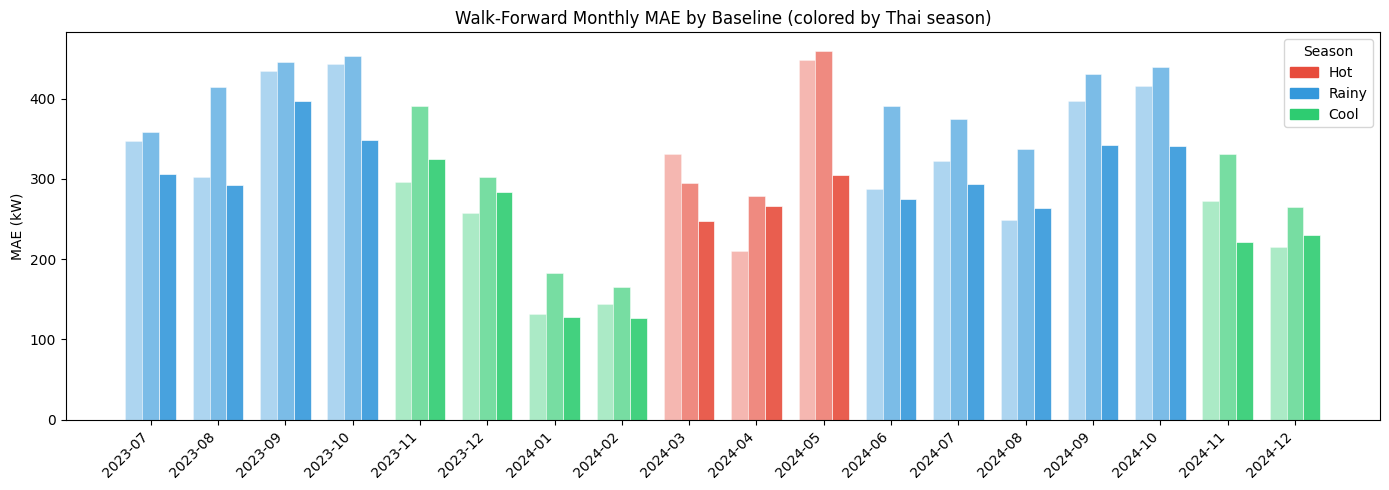

In [38]:
# Seasonal summary

season_summary = wf_results.groupby("Season")[
    ["Persist(t-1) MAE", "Persist(t-7) MAE", "HistAvg MAE"]
].mean().round(2)

season_summary = season_summary.reindex(["Hot", "Rainy", "Cool"])
print("Average MAE by Thai Season")
print("=" * 50)
display(season_summary)

# Monthly MAE chart with season coloring
season_colors = {"Hot": "#e74c3c", "Rainy": "#3498db", "Cool": "#2ecc71"}

fig, ax = plt.subplots(figsize=(14, 5))

x = range(len(wf_results))
bar_width = 0.25

for idx, (col, label) in enumerate([
    ("Persist(t-1) MAE", "Persistence (t-1)"),
    ("Persist(t-7) MAE", "Persistence (t-7)"),
    ("HistAvg MAE", "Historical Average")
]):
    offsets = [i + idx * bar_width for i in x]
    colors = [season_colors[s] for s in wf_results["Season"]]
    ax.bar(offsets, wf_results[col], bar_width, label=label, alpha=0.4 + idx * 0.25,
           color=colors, edgecolor="white", linewidth=0.5)

ax.set_xticks([i + bar_width for i in x])
ax.set_xticklabels(wf_results["Month"], rotation=45, ha="right")
ax.set_ylabel("MAE (kW)")
ax.set_title("Walk-Forward Monthly MAE by Baseline (colored by Thai season)")

from matplotlib.patches import Patch
season_patches = [Patch(color=c, label=s) for s, c in season_colors.items()]
ax.legend(handles=season_patches, loc="upper right", title="Season")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "figure_10_walkforward_monthly_mae.png", dpi=150)
plt.show()

## 8 Ridge Regression and XGBoost

The linear baseline is Ridge Regression (L2-regularized Linear Regression), alpha=1.0. L2 controls coefficient sizes for overlapping lag/rolling features. The regularization is part of the linear baseline training objective. XGBoost is evaluated with feature ablation and 10th-to-90th percentile prediction intervals. Monthly parameters are tuned independently on the initial six months only.


Optuna: 100 trials with 5-fold TimeSeriesSplit CV


  0%|          | 0/100 [00:00<?, ?it/s]

Best Optuna RMSE: 425.32 (trial 98)
Best XGBoost parameters:
{'n_estimators': 600, 'max_depth': 4, 'learning_rate': 0.009442945391855098, 'subsample': 0.5861221393902627, 'colsample_bytree': 0.45451267430901, 'min_child_weight': 10, 'gamma': 4.9036716053330975, 'reg_alpha': 0.05572322519915928, 'reg_lambda': 9.320691445340353}
Best CV RMSE: 425.32


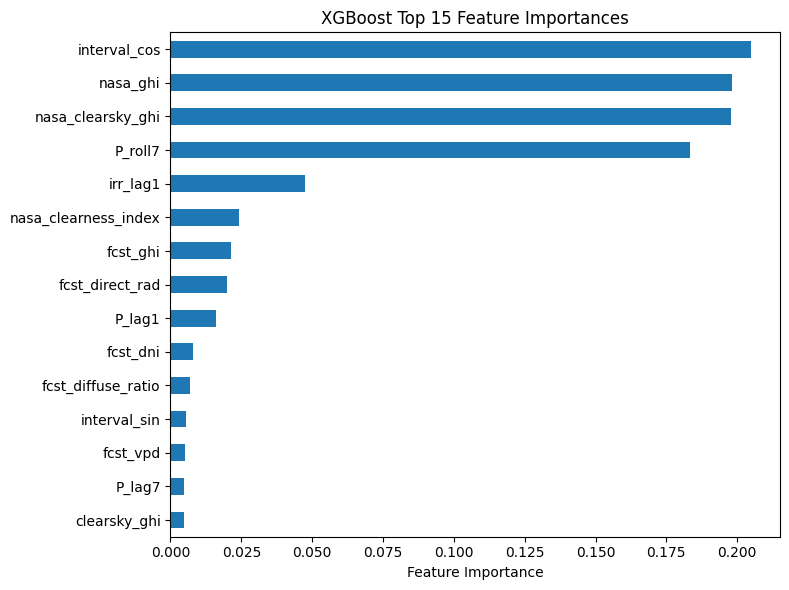

PICP (target ~80%): 92.8%
PINAW (lower is better): 0.2680


,Feature,Coefficient
35,nasa_ghi,1102.218553
22,fcst_temp,957.203365
4,irr_lag1,754.718207
24,fcst_apparent_temp,-702.769856
26,fcst_vpd,-570.947744
36,nasa_clearsky_ghi,-343.623383
43,fcst_ghi_change,341.728639
3,P_roll7,327.203239
46,fcst_temp_sq,231.707406
18,fcst_direct_rad,-160.103062


,n_estimators,max_depth,learning_rate,subsample,colsample_bytree,min_child_weight,gamma,reg_alpha,reg_lambda
0,600,4,0.009443,0.586122,0.454513,10,4.903672,0.055723,9.320691


,Model,N,MAE,RMSE,nRMSE,R2,Skill
0,Persistence (t-1) (24h),14016,312.65,686.73,0.1145,0.8009,0.0000
1,Persistence (t-1) (06-18),7008,625.27,971.18,0.1619,0.5932,0.0000
2,Persistence (t-7) (24h),14016,354.94,740.56,0.1234,0.7684,-0.1353
3,Persistence (t-7) (06-18),7008,709.84,1047.32,0.1746,0.5269,-0.1353
4,Historical Average (24h),14016,279.12,534.01,0.0890,0.8796,0.1072
5,Historical Average (06-18),7008,558.22,755.20,0.1259,0.7540,0.1072
6,Ridge Regression (24h),14016,236.91,428.40,0.0714,0.9225,0.2423
7,Ridge Regression (06-18),7008,429.13,602.64,0.1004,0.8434,0.3137
8,XGBoost (24h),14016,205.81,420.85,0.0701,0.9252,0.3417
9,XGBoost (06-18),7008,404.50,595.12,0.0992,0.8472,0.3531


,Period,N,Nominal coverage,PICP,PINAW
0,24h,14016,0.8,0.928296,0.267963
1,06-18,7008,0.8,0.860873,0.336534


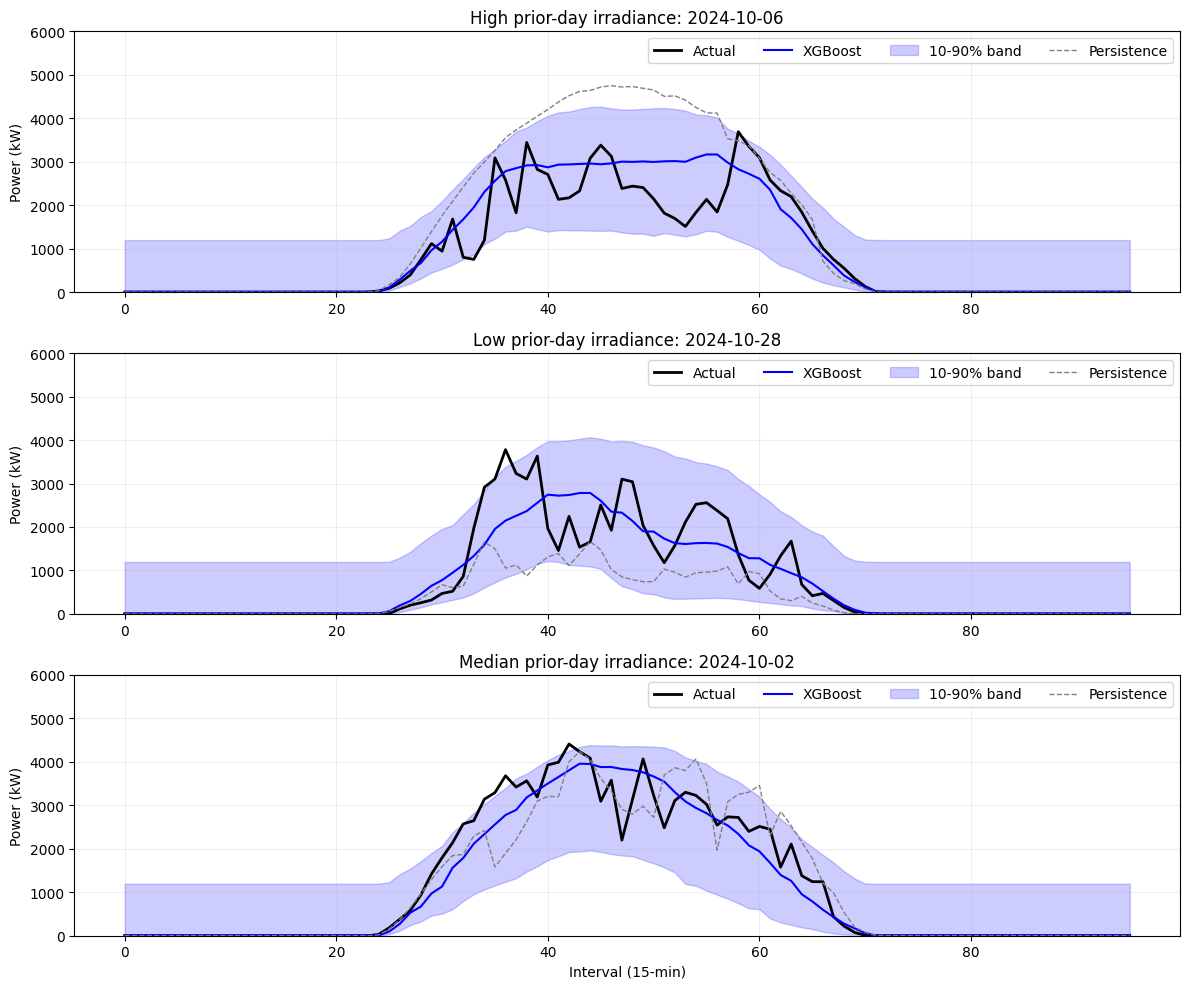

Forecast weather features added: 33 columns
Optuna: 100 trials with 5-fold TimeSeriesSplit CV


  0%|          | 0/100 [00:00<?, ?it/s]

Best Optuna RMSE: 344.90 (trial 89)
Monthly parameter selection ends: 2023-06-30 23:45:00
First monthly test starts: 2023-07-01 00:00:00
2023-07: Ridge MAE=253.35; XGBoost MAE=263.66
2023-08: Ridge MAE=243.88; XGBoost MAE=237.26
2023-09: Ridge MAE=311.79; XGBoost MAE=277.79
2023-10: Ridge MAE=295.57; XGBoost MAE=285.56
2023-11: Ridge MAE=260.47; XGBoost MAE=241.47
2023-12: Ridge MAE=227.49; XGBoost MAE=185.59
2024-01: Ridge MAE=129.34; XGBoost MAE=113.61
2024-02: Ridge MAE=138.02; XGBoost MAE=134.63
2024-03: Ridge MAE=214.92; XGBoost MAE=219.98
2024-04: Ridge MAE=176.20; XGBoost MAE=171.08
2024-05: Ridge MAE=212.04; XGBoost MAE=236.65
2024-06: Ridge MAE=187.75; XGBoost MAE=198.71
2024-07: Ridge MAE=217.31; XGBoost MAE=225.66
2024-08: Ridge MAE=195.30; XGBoost MAE=212.87
2024-09: Ridge MAE=282.98; XGBoost MAE=265.31
2024-10: Ridge MAE=270.77; XGBoost MAE=255.78
2024-11: Ridge MAE=237.15; XGBoost MAE=202.30
2024-12: Ridge MAE=182.33; XGBoost MAE=159.83


,Month,Season,Test intervals,Complete forecast days,Incomplete forecast days,Unscored forecast days,Persistence (t-1) N,Persistence (t-1) MAE,Persistence (t-1) RMSE,Persistence (t-7) N,...,Historical Average RMSE,Ridge N,Ridge MAE,Ridge RMSE,XGBoost N,XGBoost MAE,XGBoost RMSE,Parameter selection end,Test start,Parameter selection precedes test
0,2023-07,Rainy,2976,31,0,0,2976,346.78,684.69,2976,...,619.42,2976,253.35,476.82,2976,263.66,481.39,2023-06-30 23:45:00,2023-07-01 00:00:00,True
1,2023-08,Rainy,2976,31,0,0,2976,301.80,628.81,2976,...,556.93,2976,243.88,421.05,2976,237.26,444.39,2023-06-30 23:45:00,2023-08-01 00:00:00,True
2,2023-09,Rainy,2872,26,4,0,2872,434.86,881.85,2872,...,745.56,2872,311.79,527.55,2872,277.79,524.58,2023-06-30 23:45:00,2023-09-01 00:00:00,True
3,2023-10,Rainy,2976,31,0,0,2976,443.42,893.90,2976,...,651.98,2976,295.57,532.09,2976,285.56,522.52,2023-06-30 23:45:00,2023-10-01 00:00:00,True
4,2023-11,Cool,2496,26,0,4,2496,296.27,641.69,2496,...,565.63,2496,260.47,450.06,2496,241.47,443.84,2023-06-30 23:45:00,2023-11-01 00:00:00,True
5,2023-12,Cool,2784,29,0,2,2784,257.45,600.71,2784,...,488.03,2784,227.49,372.52,2784,185.59,363.51,2023-06-30 23:45:00,2023-12-01 00:00:00,True
6,2024-01,Cool,2976,31,0,0,2976,131.72,318.70,2976,...,257.17,2976,129.34,228.52,2976,113.61,223.80,2023-06-30 23:45:00,2024-01-01 00:00:00,True
7,2024-02,Cool,2784,29,0,0,2784,144.45,340.43,2784,...,289.41,2784,138.02,269.50,2784,134.63,265.69,2023-06-30 23:45:00,2024-02-01 00:00:00,True
8,2024-03,Hot,2976,31,0,0,2976,330.37,757.21,2976,...,593.43,2976,214.92,447.19,2976,219.98,443.52,2023-06-30 23:45:00,2024-03-01 00:00:00,True
9,2024-04,Hot,2880,30,0,0,2880,210.62,629.43,2880,...,519.48,2880,176.20,506.74,2880,171.08,477.74,2023-06-30 23:45:00,2024-04-01 00:00:00,True


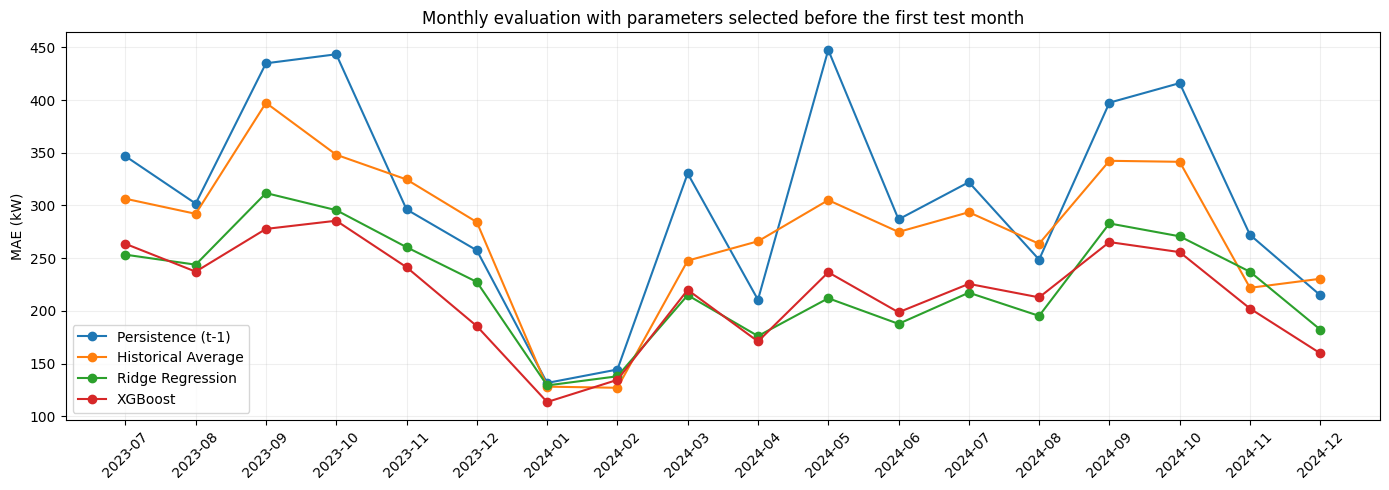

Seasonal MAE: unweighted mean of monthly MAE (kW)


,Persistence (t-1) MAE,Historical Average MAE,Ridge MAE,XGBoost MAE
Season,,,,
Hot,329.506667,272.960000,201.053333,209.236667
Rainy,355.343333,317.782222,250.966667,246.955556
Cool,219.498333,219.440000,195.800000,172.905000


In [39]:
from src.modeling import fit_advanced_models, plot_selected_forecast_days, walk_forward_with_models, plot_walk_forward_model_mae

advanced = fit_advanced_models(
    X_train, y_train, X_test, y_test, test_index, feature_names,
    baseline_results=baseline_results.copy(), output_dir=OUTPUT_DIR,
    tscv=tscv, impute_feature_columns=feature_names,
    plant_capacity_kw=PLANT_CAPACITY_KW, random_state=RANDOM_STATE,
    search_n_iter=XGB_SEARCH_ITER,
)
display(advanced["ridge_top_coefficients"][["Feature","Coefficient"]])
display(pd.DataFrame([advanced["best_params"]]))
results_df = advanced["results_df"]
display(results_df)
display(advanced["interval_metrics"])
selected_days = plot_selected_forecast_days(
    test_index, y_test.to_numpy(), advanced["y_pred_xgb"],
    advanced["y_low"],advanced["y_high"],persist1_pred,
    df_test_feat["irr_lag1"].to_numpy(),OUTPUT_DIR,
)

# No hold-out best_params are passed to the earlier monthly windows.
wf_models = walk_forward_with_models(
    df_clean_raw, feature_names,
    lambda raw: build_features(raw, forecast_weather=forecast_weather),
    output_dir=OUTPUT_DIR,
    min_train_months=6, random_state=RANDOM_STATE,
    search_n_iter=XGB_SEARCH_ITER, capacity_kw=PLANT_CAPACITY_KW,
)
assert (pd.to_datetime(wf_models["Parameter selection end"]) < pd.to_datetime(wf_models["Test start"])).all()
assert wf_models["Test intervals"].to_list() == wf_results["Test intervals"].to_list()
display(wf_models)
plot_walk_forward_model_mae(wf_models,OUTPUT_DIR)
seasonal_models = wf_models.groupby("Season")[[
    "Persistence (t-1) MAE","Historical Average MAE","Ridge MAE","XGBoost MAE"
]].mean().reindex(["Hot","Rainy","Cool"])
print("Seasonal MAE: unweighted mean of monthly MAE (kW)")
display(seasonal_models)
seasonal_models.to_csv(OUTPUT_DIR/"table_13_seasonal_models.csv")


## 8.1 Forecast weather impact summary

Compare model performance with and without day-ahead weather forecasts.
If forecast features are present, the ablation table shows their
marginal contribution for XGBoost vs Ridge.


In [40]:
fcst_cols_used = [c for c in feature_names if c.startswith("fcst_") or c == "clear_sky_index"]
if fcst_cols_used:
    print(f"Forecast features in model: {fcst_cols_used}")
    print()
    # Show 24h comparison only for clean summary
    full_day = results_df[results_df["Model"].str.contains("24h")]
    print("24-hour model comparison:")
    display(full_day[["Model", "MAE", "RMSE", "nRMSE", "R2", "Skill"]])
    print()
    print("Seasonal MAE with forecast weather features:")
    display(seasonal_models)
else:
    print("No forecast weather features found.")
    print("Run python -m src.fetch_weather, then re-run this notebook.")

Forecast features in model: ['fcst_ghi', 'fcst_direct_rad', 'fcst_diffuse_rad', 'fcst_dni', 'fcst_sunshine_sec', 'fcst_temp', 'fcst_dewpoint', 'fcst_apparent_temp', 'fcst_humidity', 'fcst_vpd', 'fcst_pressure', 'fcst_precip', 'fcst_cloud', 'fcst_cloud_low', 'fcst_cloud_mid', 'fcst_cloud_high', 'fcst_wind', 'fcst_windgusts', 'clear_sky_index', 'fcst_ghi_change', 'fcst_diffuse_ratio', 'fcst_cloud_x_ghi', 'fcst_temp_sq']

24-hour model comparison:


,Model,MAE,RMSE,nRMSE,R2,Skill
0,Persistence (t-1) (24h),312.65,686.73,0.1145,0.8009,0.0000
2,Persistence (t-7) (24h),354.94,740.56,0.1234,0.7684,-0.1353
4,Historical Average (24h),279.12,534.01,0.0890,0.8796,0.1072
6,Ridge Regression (24h),236.91,428.40,0.0714,0.9225,0.2423
8,XGBoost (24h),205.81,420.85,0.0701,0.9252,0.3417
10,XGBoost (lags only) (24h),280.61,552.42,0.0921,0.8711,0.1025
12,XGBoost (lags+weather) (24h),269.90,536.09,0.0893,0.8787,0.1367
14,XGBoost (lags+weather+forecast) (24h),242.19,487.95,0.0813,0.8995,0.2254
16,XGBoost (lags+forecast) (24h),242.15,487.55,0.0813,0.8996,0.2255



Seasonal MAE with forecast weather features:


,Persistence (t-1) MAE,Historical Average MAE,Ridge MAE,XGBoost MAE
Season,,,,
Hot,329.506667,272.960000,201.053333,209.236667
Rainy,355.343333,317.782222,250.966667,246.955556
Cool,219.498333,219.440000,195.800000,172.905000


## 9 Audit scope and result interpretation

The source audit compares daily source rows and missing-P counts with loaded data; it is not an exact value-by-value validation. Timestamp coverage, complete-target days, retained policy days, and scored forecast days are separate counts. The earlier 548/731 result comprises 548 complete and 5 partial loaded days, plus 178 dates absent from the earlier loaded dataset. Do not interpret the change as newly collected measurements.

Feature audit PASS checks lag/rolling/calendar definitions. Causal cleaning and chronological parameter selection are separate safeguards. Recompute all reported metrics after running this revision.


In [41]:
from src.data_quality import run_feature_availability_audit
feature_availability_audit = run_feature_availability_audit(
    df_full_imputed, df_features, feature_names, OUTPUT_DIR,
)
print("Report counts from this run:")
print("Calendar dates:",len(completeness_audit))
print("Complete target dates:",int(completeness_audit.complete_96.sum()))
print("Retained policy dates:",int((~day_quality_log.excluded).sum()))
print("Scored hold-out intervals:",len(y_test))
print("Full-day and daytime scores must be interpreted separately.")


Feature availability audit: PASS


,Feature,Source,Max source lag (days),Available before forecast,Forecast issue deadline,Value provenance check
0,P_lag1,"P, day D-1",1,True,D-1 23:55,PASS
1,P_lag2,"P, day D-2",2,True,D-1 23:55,PASS
2,P_lag7,"P, day D-7",7,True,D-1 23:55,PASS
3,P_roll7,"P, same interval during days D-1 to D-7",7,True,D-1 23:55,PASS
4,amb_lag1,"AMBTEMP, day D-1",1,True,D-1 23:55,PASS
5,clear_sky_index,Open-Meteo day-ahead weather forecast for day D,0,True,D-1 23:55,PASS
6,clearsky_ghi,Open-Meteo day-ahead weather forecast for day D,0,True,D-1 23:55,PASS
7,dow,calendar known at forecast time,0,True,D-1 23:55,PASS
8,doy_cos,calendar known at forecast time,0,True,D-1 23:55,PASS
9,doy_sin,calendar known at forecast time,0,True,D-1 23:55,PASS


Report counts from this run:
Calendar dates: 731
Complete target dates: 722
Retained policy dates: 728
Scored hold-out intervals: 14016
Full-day and daytime scores must be interpreted separately.
